# Baryonische akustische Oszillationen

Das Notebook wertet die BAO-Messungen von DESI DR2 aus: 13 Entfernungen von z = 0.3 bis 2.3 mit Kovarianz. Dazu gehören:
- der Alcock-Paczynski-Test,
- Ω_m und h·r_d nur aus BAO,
- der Schallhorizont r_d als Integral,
- die inverse Entfernungsleiter mit der Nukleosynthese und $\theta_\star$,
- die Spannung zwischen BAO, Hintergrundstrahlung und Supernovae,
- ein Fit mit zeitlich veränderlicher Dunkler Energie (w₀w_aCDM) samt eigenem MCMC.

Alles wird mit den Ergebnissen von DESI DR2 verglichen.

Was verrät der Schallhorizont in der Verteilung der Galaxien über die Hubble-Konstante, und ändert sich die Dunkle Energie mit der Zeit?

#### **Hintergrund**

Die Schallwellen im Plasma des frühen Universums, deren Spuren man in der Hintergrundstrahlung als akustische Peaks sieht, haben auch die Materie geprägt. Um jede Überdichte lief eine Schallwelle nach außen, bis die Baryonen etwa 380 000 Jahre nach dem Urknall vom Licht frei kamen. Dann blieb eine Schale aus Baryonen im Abstand $r_d \approx 147$ Mpc stehen (mitbewegt gemessen). Aus diesen Schalen und den Überdichten in ihrer Mitte wuchsen später Galaxien. Deshalb findet man heute ein Paar Galaxien im Abstand von 147 Mpc etwas häufiger als bei 130 oder 160 Mpc. Das sind die **baryonischen akustischen Oszillationen (BAO)**: ein eingebautes Lineal, dessen Länge die Physik des frühen Universums festlegt.

2005 fanden Eisenstein et al. in den roten Galaxien des SDSS und Cole et al. im 2dF-Survey zum ersten Mal diesen Buckel in der Korrelationsfunktion. Die Durchmusterungen BOSS und eBOSS vermaßen ihn bis z ≈ 2.3. Seit 2021 beobachtet das Dark Energy Spectroscopic Instrument (DESI) am 4-m-Mayall-Teleskop auf dem Kitt Peak mit 5000 Glasfasern gleichzeitig. Die zweite Datenfreigabe (DR2, März 2025) enthält knapp 15 Millionen Galaxien und Quasare aus drei Jahren.

Was Forschende damit tun:
- Sie messen die räumliche Verteilung der Galaxien, rechnen die Bewegungen teilweise zurück (Rekonstruktion) und passen eine Schablone mit dem BAO-Buckel an. Daraus folgen Entfernungen in Einheiten von $r_d$, quer und längs zur Sichtlinie.
- Sie kombinieren diese Entfernungen mit der Hintergrundstrahlung und mit Supernovae.

Die BAO-Ergebnisse von DESI haben die Kosmologie seit 2024 bewegt. In ΛCDM passen sie mit einem kleineren Ω_m als Planck, und alle Kombinationen ziehen ein Modell vor, in dem die Dunkle Energie nicht konstant ist. Mit der Hintergrundstrahlung ist der Vorzug 3.1σ, mit Supernovae dazu 2.8 bis 4.2σ.

Dieses Notebook rechnet das nach: von den 13 Messwerten über ein Ω_m ohne Maßstab und eine Hubble-Konstante ohne Cepheiden bis zur Frage, ob w = −1 ist.

<a id="landkarte"></a>Landkarte:

- **Daten**
  - [Die Messungen von DESI DR2 (Schritt 1)](#exp-1): 13 Entfernungen in Einheiten von r_d, auf 0.7 bis 4 % genau; die meisten 1 bis 4 % unter Planck-ΛCDM (χ² = 30 bei 13 Werten).
- **Reduktion**
  - [Alcock-Paczynski: die Form ohne Maßstab (Schritt 2)](#exp-2): Ω_m = 0.298 ± 0.017 ohne r_d und H₀.
  - [BAO und Supernovae im selben Diagramm (Schritt 3)](#exp-3): Mit r_d von Planck und M_B der Cepheiden liegen die beiden Leitern 8.9 % auseinander.
- **Eigene Messung**
  - [Ω_m und h·r_d nur aus den BAO (Schritt 4)](#exp-4): 0.2972 ± 0.0086 und 101.55 ± 0.74 Mpc, wie bei DESI.
  - [Der Schallhorizont r_d (Schritt 5)](#exp-5): 147.09 Mpc, 1.8 % mehr als r* der Hintergrundstrahlung.
  - [Die inverse Entfernungsleiter (Schritt 6)](#exp-6): H₀ = 68.53 ± 0.60 aus BAO und BBN, 3.7σ unter SH0ES.
- **Modell und Fit**
  - [Der Buckel in der Verteilung der Galaxien (Schritt 7)](#exp-7): r²ξ(r) hat ihn bei 149 Mpc; ohne Baryonen fehlt er.
  - [BAO gegen Hintergrundstrahlung in ΛCDM (Schritt 8)](#exp-8): 1.8σ Abstand; zusammen H₀ = 68.36 ± 0.30.
  - [Drei Messungen von Ω_m (Schritt 9)](#exp-9): BAO 0.297, CMB 0.316, Supernovae 0.331.
  - [Dunkle Energie mit w₀ und w_a (Schritt 10)](#exp-10): Δχ² = −7.9 (2.3σ) mit CMB, −7.5 mit CMB und Supernovae.
  - [Welche Werte von w₀ und w_a erlaubt sind (Schritt 11)](#exp-11): mit Pantheon+ w₀ = −0.847 ± 0.054, w_a = −0.55 ± 0.22.
  - [Was w₀ und w_a für die Dunkle Energie bedeuten (Schritt 12)](#exp-12): w kreuzt −1 bei z ≈ 0.4, die Dichte hat dort ein Maximum.
- **Eigene Messung gegen den Katalog**
  - [Gegen DESI DR2 und die Entfernungsleiter (Schritt 13)](#exp-13): alle eigenen Werte innerhalb von 0.2 km/s/Mpc von DESI, 3.7 bis 4.7σ unter SH0ES.

Verwandte Notebooks: der Schallhorizont in der Hintergrundstrahlung, $\theta_\star$ und die Dichten aus den Peakhöhen in [Die akustischen Peaks](https://github.com/deltorobarba/science/blob/main/astro/cosmology_cmbpeaks.ipynb); die Supernovae von Pantheon+, M_B aus den Cepheiden und Ω_m in [Das Hubble-Diagramm](https://github.com/deltorobarba/science/blob/main/astro/cosmology_hubblediagram.ipynb); ob eine Leere um uns die Spannung erklärt, in [Eine lokale Leere?](https://github.com/deltorobarba/science/blob/main/astro/cosmology_localvoid.ipynb); das Lineal $r_d$ mit einer Uhr statt mit dem frühen Universum geeicht in [Kosmische Chronometer](https://github.com/deltorobarba/science/blob/main/astro/cosmology_chronometers.ipynb); H₀ aus einer Gravitationswelle in [Standardsirenen](https://github.com/deltorobarba/science/blob/main/astro/cosmology_sirens.ipynb).

#### **Theorie**

##### *1. Der Schallhorizont in der Materie*

Vor der Rekombination bewegten sich Baryonen und Photonen als eine Flüssigkeit, in der Schall mit $c_s = c/\sqrt{3(1+R)}$ lief, $R = 3\rho_b/4\rho_\gamma$ (siehe [Die akustischen Peaks](https://github.com/deltorobarba/science/blob/main/astro/cosmology_cmbpeaks.ipynb), Theorie, Abschnitt 3). Die Photonen entkoppeln bei $z_\star \approx 1090$. Die Baryonen spüren den Druck der Photonen noch etwas länger, bis $z_d \approx 1060$ (**Drag-Epoche**), weil auf jedes Baryon über eine Milliarde Photonen kommen. Die Strecke, die der Schall bis dahin zurücklegt, ist

$$r_d = \int_{z_d}^{\infty} \frac{c_s(z)}{H(z)}\,dz \approx 147\ \text{Mpc} .$$

Sie ist um etwa 2 % größer als der Schallhorizont $r_\star$ bei $z_\star$, der die Peaks der Hintergrundstrahlung festlegt. Wie $r_\star$ hängt $r_d$ nur von den physikalischen Dichten $\omega_b = \Omega_b h^2$ und $\omega_{cb} = (\Omega_b + \Omega_c) h^2$ ab, nicht von $H_0$. Für $z_d$ nimmt das Notebook die Näherung von Eisenstein & Hu (1998, Gl. 4), für $z_\star$ die von Hu & Sugiyama (1996). Beide sind an den Werten von Planck geeicht, weil die Näherungen um 0.2 % (z*) und 4 % (z_d) daneben liegen.

##### *2. Drei Entfernungen*

Ein Lineal bekannter Länge, quer zur Sichtlinie in der Rotverschiebung z gesehen, erscheint unter dem Winkel $\Delta\theta = r_d/D_M(z)$. Längs der Sichtlinie erstreckt es sich über die Rotverschiebung $\Delta z = r_d H(z)/c$. DESI misst deshalb drei Verhältnisse:

$$\frac{D_M(z)}{r_d}, \qquad \frac{D_H(z)}{r_d} = \frac{c}{H(z)\,r_d}, \qquad \frac{D_V(z)}{r_d} = \frac{\left[z\,D_M(z)^2 D_H(z)\right]^{1/3}}{r_d},$$

mit der mitbewegten Entfernung $D_M = \int_0^z c\,dz'/H(z')$ im flachen Universum. $D_V$ ist ein Mittel über alle Richtungen; man nimmt es, wenn eine Stichprobe zu klein ist, um quer und längs zu trennen (BGS bei z = 0.295).

Alle drei sind Verhältnisse zu $r_d$. Schreibt man $H(z) = H_0\,E(z)$, ist

$$\frac{D_M}{r_d} = \frac{c}{H_0 r_d} \int_0^z \frac{dz'}{E(z')} ,$$

und $E(z)$ hängt in ΛCDM nur von $\Omega_m$ ab. BAO allein messen deshalb nur zwei Zahlen: $\Omega_m$ und das Produkt $h\,r_d$, nicht $H_0$ und $r_d$ getrennt.

##### *3. Der Alcock-Paczynski-Test*

Das Verhältnis

$$F_\text{AP}(z) = \frac{D_M(z)}{D_H(z)} = E(z) \int_0^z \frac{dz'}{E(z')}$$

enthält weder $r_d$ noch $H_0$. Es vergleicht die Ausdehnung eines kugelförmigen Objekts quer und längs zur Sichtlinie und misst nur die Form der Expansionsgeschichte (Alcock & Paczynski 1979). In ΛCDM legt es $\Omega_m$ allein fest.

##### *4. Die inverse Entfernungsleiter*

Die übliche Entfernungsleiter misst $H_0$ von nah nach fern: Parallaxen, Cepheiden, Supernovae. Die **inverse Entfernungsleiter** beginnt am anderen Ende. Die Länge $r_d$ folgt aus der Physik des frühen Universums, wenn man $\omega_b$ und $\omega_{cb}$ kennt; BAO messen $h\,r_d$, und damit ist $h$ bestimmt.

$\omega_b$ kann aus der **Nukleosynthese (BBN)** kommen: Wie viel Deuterium in den ersten Minuten übrig bleibt, hängt von der Dichte der Baryonen ab. Aus dem gemessenen D/H in Gaswolken vor fernen Quasaren folgt $\omega_b = 0.02218 \pm 0.00055$ (Schöneberg 2024, wie bei DESI). $\omega_{cb}$ folgt dann aus $\Omega_m$ (aus den BAO) und $h$ selbst.

##### *5. Dunkle Energie mit w₀ und w_a*

In ΛCDM ist die Dunkle Energie eine kosmologische Konstante mit Druck $p = w\rho c^2$ und $w = -1$; ihre Dichte bleibt bei der Expansion gleich. Die übliche Erweiterung (Chevallier & Polarski 2001, Linder 2003) lässt $w$ mit dem Skalenfaktor $a = 1/(1+z)$ laufen:

$$w(a) = w_0 + w_a (1 - a), \qquad \frac{\rho_\text{DE}(a)}{\rho_\text{DE,0}} = a^{-3(1 + w_0 + w_a)}\, e^{-3 w_a (1 - a)} .$$

Heute ist $w = w_0$, früh war $w = w_0 + w_a$. Mit $w < -1$ (**phantom**) wächst die Dichte der Dunklen Energie mit der Zeit, mit $w > -1$ fällt sie. Bei $w_0 > -1$ und $w_a < 0$ war $w$ früher unter −1 und ist heute darüber; die Dichte hatte dann ein Maximum.

Ein Modell mit zwei zusätzlichen Parametern passt immer mindestens so gut. Wie viel besser es passen muss, beantwortet $\Delta\chi^2$: Ist ΛCDM richtig, folgt $-\Delta\chi^2$ einer χ²-Verteilung mit 2 Freiheitsgraden. Ihre Überschreitungswahrscheinlichkeit $p$ wird als „Nσ“ einer Normalverteilung angegeben (zweiseitig); $\Delta\chi^2 = -8$ entspricht 2.4σ.

##### *6. Die Hintergrundstrahlung in drei Zahlen*

Für späte Physik wie die Dunkle Energie trägt die Hintergrundstrahlung vor allem drei Zahlen bei: den Winkel $\theta_\star = r_\star/D_M(z_\star)$ und die Dichten $\omega_b$ und $\omega_{cb}$. DESI benutzt deshalb wahlweise eine **komprimierte Likelihood**: eine dreidimensionale Normalverteilung mit Mittelwert $(\theta_\star, \omega_b, \omega_{cb}) = (0.01041, 0.02223, 0.14208)$ und Kovarianz aus Läufen von CamSpec (Lemos & Lewis 2023; DESI DR2, Anhang A). Sie enthält nichts, was von der Physik nach der Rekombination abhängt, etwa das Lensing.

##### *7. Markov-Ketten (MCMC)*

Die Verteilung der Parameter, die mit den Daten verträglich sind, tastet ein **Metropolis-Algorithmus** ab. Von einem Punkt $p$ aus schlägt er einen zufälligen Nachbarn $q$ vor. Ist $\chi^2(q) < \chi^2(p)$, springt er immer dorthin, sonst nur mit der Wahrscheinlichkeit $e^{-[\chi^2(q) - \chi^2(p)]/2}$. Nach einer Einlaufphase sind die besuchten Punkte Stichproben der Posterior-Verteilung. Die Vorschläge zieht er aus einer Normalverteilung mit der Kovarianz der Parameter, gestreckt mit dem Faktor $2.38^2/d$ für $d$ Parameter (Gelman et al. 1996). DESI benutzt dafür das Programm Cobaya.

**Fachbegriffe:**
- **Tracer:** die Objektklasse, deren Verteilung gemessen wird: helle Galaxien (BGS), leuchtkräftige rote Galaxien (LRG), Galaxien mit Emissionslinien (ELG), Quasare (QSO) und der Lyman-α-Wald, das Absorptionsmuster des Wasserstoffs vor fernen Quasaren.
- **Effektive Rotverschiebung $z_\text{eff}$:** die Rotverschiebung, an der eine Messung über einen breiten Bereich als Punktmessung gilt.
- **Profil gegen Posterior:** Ein Profil minimiert χ² über die übrigen Parameter, eine Posterior-Verteilung mittelt über sie. Bei schief verteilten Parametern wie $w_a$ unterscheiden sich die beiden; DESI gibt Mittelwerte der Posterior an.

#### **Daten**

- **DESI DR2 BAO** (DESI Collaboration 2025, Tabelle IV): 13 Messwerte von $D_V/r_d$, $D_M/r_d$ und $D_H/r_d$ für sieben Stichproben bei $z_\text{eff}$ = 0.295 bis 2.33, mit der 13 × 13-Kovarianzmatrix. Die Textdateien kommen aus dem Repository `CobayaSampler/bao_data` auf GitHub, das auch die Likelihood von DESI in Cobaya speist.
- **Pantheon+** (Scolnic et al. 2022, Brout et al. 2022): dieselben Supernovae wie in [Das Hubble-Diagramm](https://github.com/deltorobarba/science/blob/main/astro/cosmology_hubblediagram.ipynb), hier die 1590 Lichtkurven mit z > 0.01 und ihre Kovarianzmatrix. Ihre absolute Helligkeit bleibt frei; sie tragen nur die Form der Expansionsgeschichte bei (wie bei DESI).
- **Vorwissen aus dem frühen Universum:** die komprimierte CMB-Likelihood von DESI (Anhang A), ω_b aus der Nukleosynthese (Schöneberg 2024) und 100 $\theta_\star$ = 1.04110 ± 0.00053 (DESI Gl. 16), dazu Planck 2018 als Bezug und SH0ES. Alles als Konstanten im Code.

**Hintergrund & Fachbegriffe:**
- **Kovarianzmatrix der BAO:** Zu jeder Stichprobe gehören $D_M$ und $D_H$ aus denselben Galaxien; ihre Fehler sind korreliert (Korrelationskoeffizient −0.35 bis −0.49 bei DESI DR2). Zwischen verschiedenen Stichproben ist die Matrix null.
- **Bezugsmodell:** Planck 2018 ΛCDM mit h = 0.6736, ω_b = 0.02237, ω_c = 0.1200, $r_d$ = 147.09 Mpc. Die Messwerte werden durch seine Vorhersage geteilt, damit kleine Abweichungen sichtbar werden.

In [1]:
import os
import time
import urllib.request
from pathlib import Path

ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage, optimize, stats

C_KMS, OMEGA_G, OMEGA_NU = 299792.458, 2.4728e-5, 0.00064   # c [km/s]; ω_γ für 2.7255 K; ω_ν eines Neutrinos mit 0.06 eV
DESI_URL = "https://raw.githubusercontent.com/CobayaSampler/bao_data/master/desi_bao_dr2/"
PANTHEON_URL = "https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/"
DESI_DIR, PANTHEON = ASTRODATA / "desi", ASTRODATA / "pantheon"
TRACERS = {0.295: "BGS", 0.51: "LRG1", 0.706: "LRG2", 0.934: "LRG3+ELG1", 1.321: "ELG2", 1.484: "QSO", 2.33: "Lyα"}
PLANCK = dict(h=0.6736, wb=0.02237, wc=0.1200, rd=147.09, zd=1059.94, zstar=1089.92, theta=1.04110, Om=0.3153, H0=(67.36, 0.54))
CMB_MEAN = np.array([0.01041, 0.02223, 0.14208])                     # θ*, ω_b, ω_cb (DESI DR2, Gl. A1)
CMB_COV = 1e-9 * np.array([[0.006621, 0.12444, -1.1929],
                           [0.12444, 21.344, -94.001],
                           [-1.1929, -94.001, 1488.4]])               # Gl. A2
BBN = (0.02218, 0.00055)                                             # ω_b aus D/H (Schöneberg 2024; DESI Gl. 14)
THETA = (1.04110, 0.00053)                                           # 100 θ* (DESI Gl. 16)
H0_SH0ES = (73.04, 1.04)                                             # Riess et al. 2022
M_B_CEPHEID = -19.249                                                # absolute Helligkeit aus Das Hubble-Diagramm
W_PRIOR = dict(w0=(-3.0, 1.0), wa=(-3.0, 2.0))                       # flache Priors wie bei DESI, dazu w₀ + w_a < 0


def download(url, path, check, timeout=300):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=timeout) as r:
            data = r.read()
        if not check(data):
            raise OSError(f"{path.name}: unerwarteter Inhalt")
        path.write_bytes(data)
    return path


name = "desi_gaussian_bao_ALL_GCcomb_"
tab = np.loadtxt(download(DESI_URL + name + "mean.txt", DESI_DIR / (name + "mean.txt"), lambda d: d.startswith(b"# [z]")), dtype=str)
Z_BAO, Y_BAO, KIND = tab[:, 0].astype(float), tab[:, 1].astype(float), tab[:, 2]
COV_BAO = np.loadtxt(download(DESI_URL + name + "cov.txt", DESI_DIR / (name + "cov.txt"), lambda d: d[:1].isdigit()))
IC_BAO = np.linalg.inv(COV_BAO)
ERR_BAO = np.sqrt(np.diag(COV_BAO))

SN = pd.read_csv(download(PANTHEON_URL + "Pantheon%2BSH0ES.dat", PANTHEON / "Pantheon+SH0ES.dat", lambda d: d.startswith(b"CID")), sep=r"\s+")
N = len(SN)
COV = np.loadtxt(download(PANTHEON_URL + "Pantheon%2BSH0ES_STAT%2BSYS.cov", PANTHEON / "Pantheon+SH0ES_STAT+SYS.cov",
                          lambda d: d.split(b"\n", 1)[0].strip() == b"1701"), skiprows=1).reshape(N, N)
COV = (COV + COV.T) / 2                                              # die Textdatei ist auf 8 Stellen gerundet
use = SN["zHD"].values > 0.01
Z_SN, ZHEL_SN, M_SN = SN["zHD"].values[use], SN["zHEL"].values[use], SN["m_b_corr"].values[use]
COV_SN = COV[np.ix_(use, use)]
IC_SN = np.linalg.inv(COV_SN)
IC_SN_SUM = IC_SN.sum()
IC_CMB = np.linalg.inv(CMB_COV)

print(f"DESI DR2: {len(Y_BAO)} Messwerte bei z = {Z_BAO.min()} bis {Z_BAO.max()}; Arten: "
      + ", ".join(f"{k} {np.sum(KIND == k)}" for k in ["DV_over_rs", "DM_over_rs", "DH_over_rs"]))
print(f"Pantheon+: {use.sum()} Lichtkurven mit z > 0.01 (von {N}); CMB-Likelihood: 100 θ* = {100 * CMB_MEAN[0]:.3f} ± "
      f"{100 * np.sqrt(CMB_COV[0, 0]):.5f}, ω_b = {CMB_MEAN[1]} ± {np.sqrt(CMB_COV[1, 1]):.5f}, ω_cb = {CMB_MEAN[2]} ± {np.sqrt(CMB_COV[2, 2]):.4f}")

DESI DR2: 13 Messwerte bei z = 0.295 bis 2.33; Arten: DV_over_rs 1, DM_over_rs 6, DH_over_rs 6
Pantheon+: 1590 Lichtkurven mit z > 0.01 (von 1701); CMB-Likelihood: 100 θ* = 1.041 ± 0.00026, ω_b = 0.02223 ± 0.00015, ω_cb = 0.14208 ± 0.0012


**Werkzeuge: Expansion, Entfernungen, Schallhorizonte, χ² und Fits** (Theorie, Abschnitte 1 bis 7).
- `E` ist H(z)/H₀ mit Strahlung, einem massiven Neutrino, Materie und Dunkler Energie (w₀, w_a).
- `cosmo` integriert einmal über ein Gitter in ln(1+z) bis z = 10⁸ und liefert $D_M(z)$, $r_d$, $r_\star$ und $\theta_\star$.
- `bao_model` sagt die 13 Messwerte voraus.
- Die χ²-Funktionen vergleichen das Modell mit BAO, Supernovae (die absolute Helligkeit ist analytisch herausgerechnet), der Hintergrundstrahlung, BBN und $\theta_\star$.
- `fit` sucht das Minimum, `covariance` die Fehler aus der Krümmung von χ², `sigma` rechnet Δχ² in σ um.
- `ellipse` zeichnet Fehlerellipsen.

In [2]:
X = np.linspace(0, np.log(1 + 1e8), 6001)                            # Gitter in ln(1+z)
ZG = np.expm1(X)
WM_PLANCK = PLANCK["wb"] + PLANCK["wc"] + OMEGA_NU


def E(z, h, wm, w0=-1.0, wa=0.0):
    # H(z)/H₀ (flach): Photonen und zwei masselose Neutrinos als Strahlung, das massive Neutrino geht von Strahlung in Materie
    # über (Wurzel aus der Summe der Quadrate), Dunkle Energie mit w(a) = w₀ + w_a (1 − a)
    a = 1 / (1 + z)
    o_rad = OMEGA_G * (1 + 0.2271 * 3.046 * 2 / 3) / h**2
    o_nu1 = OMEGA_G * 0.2271 * 3.046 / 3 / h**2
    o_nu = np.sqrt((o_nu1 / a**4) ** 2 + (OMEGA_NU / h**2 / a**3) ** 2)
    o_m = (wm - OMEGA_NU) / h**2
    o_de = 1 - o_m - o_rad - np.sqrt(o_nu1**2 + (OMEGA_NU / h**2) ** 2)
    f_de = a ** (-3 * (1 + w0 + wa)) * np.exp(-3 * wa * (1 - a))
    return np.sqrt(o_rad / a**4 + o_nu + o_m / a**3 + o_de * f_de)


def z_star(wb, wm):
    # Hu & Sugiyama (1996), Gl. E1
    g1 = 0.0783 * wb**-0.238 / (1 + 39.5 * wb**0.763)
    g2 = 0.560 / (1 + 21.1 * wb**1.81)
    return 1048 * (1 + 0.00124 * wb**-0.738) * (1 + g1 * wm**g2)


def z_drag(wb, wm):
    # Eisenstein & Hu (1998), Gl. 4
    b1 = 0.313 * wm**-0.419 * (1 + 0.607 * wm**0.674)
    b2 = 0.238 * wm**0.223
    return 1291 * wm**0.251 / (1 + 0.659 * wm**0.828) * (1 + b1 * wb**b2)


K_ZSTAR = PLANCK["zstar"] / z_star(PLANCK["wb"], WM_PLANCK)          # Eichung der Näherungen an Planck
K_ZDRAG = PLANCK["zd"] / z_drag(PLANCK["wb"], WM_PLANCK)


def cosmo(h, wb, wcb, w0=-1.0, wa=0.0):
    wm = wcb + OMEGA_NU
    f = (1 + ZG) / E(ZG, h, wm, w0, wa)                                # dz/E = (1+z)/E · d ln(1+z)
    dm = C_KMS / (100 * h) * np.concatenate([[0.0], np.cumsum((f[1:] + f[:-1]) / 2 * np.diff(X))])
    g = f / np.sqrt(3 * (1 + 3 * wb / (4 * OMEGA_G) / (1 + ZG)))       # c_s/c · dz/E
    seg = (g[1:] + g[:-1]) / 2 * np.diff(X)
    rs_above = C_KMS / (100 * h) * np.concatenate([np.cumsum(seg[::-1])[::-1], [0.0]])   # ∫_z^∞ c_s dz/H [Mpc]
    zs, zd = K_ZSTAR * z_star(wb, wm), K_ZDRAG * z_drag(wb, wm)
    at = lambda arr, z: np.interp(np.log1p(z), X, arr)
    return dict(h=h, wb=wb, wcb=wcb, wm=wm, w0=w0, wa=wa, dm=dm, rs_above=rs_above, zs=zs, zd=zd,
                rd=at(rs_above, zd), rstar=at(rs_above, zs), theta=at(rs_above, zs) / at(dm, zs))


def distances(c, z):
    DM = np.interp(np.log1p(z), X, c["dm"])
    DH = C_KMS / (100 * c["h"] * E(z, c["h"], c["wm"], c["w0"], c["wa"]))
    return DM, DH, (z * DM**2 * DH) ** (1 / 3)


def bao_model(c):
    DM, DH, DV = distances(c, Z_BAO)
    return np.select([KIND == "DM_over_rs", KIND == "DH_over_rs"], [DM, DH], DV) / c["rd"]


def chi2_bao(c):
    r = Y_BAO - bao_model(c)
    return r @ IC_BAO @ r


def chi2_sn(c):
    # m_B − 5 log₁₀(D_L/Mpc) − 25 = M_B; über M_B analytisch minimiert
    r = M_SN - 5 * np.log10((1 + ZHEL_SN) * np.interp(np.log1p(Z_SN), X, c["dm"])) - 25
    a = IC_SN @ r
    return r @ a - a.sum() ** 2 / IC_SN_SUM


def chi2_cmb(c):
    d = np.array([c["theta"], c["wb"], c["wcb"]]) - CMB_MEAN
    return d @ IC_CMB @ d


PARTS = dict(BAO=chi2_bao, SN=chi2_sn, CMB=chi2_cmb,
             BBN=lambda c: ((c["wb"] - BBN[0]) / BBN[1]) ** 2,
             THETA=lambda c: ((100 * c["theta"] - THETA[0]) / THETA[1]) ** 2)


def unpack(p, model):
    return (*p[:3], p[3], p[4]) if model == "w0wa" else (*p[:3], -1.0, 0.0)


def total(p, data, model="lcdm"):
    h, wb, wcb, w0, wa = unpack(p, model)
    if not (0.4 < h < 1.0 and 0.005 < wb < 0.05 and 0.05 < wcb < 0.3 and W_PRIOR["w0"][0] <= w0 <= W_PRIOR["w0"][1]
            and W_PRIOR["wa"][0] <= wa <= W_PRIOR["wa"][1] and w0 + wa < 0):
        return 1e10
    c = cosmo(h, wb, wcb, w0, wa)
    return sum(PARTS[d](c) for d in data)


START = dict(lcdm=[0.68, 0.0222, 0.142], w0wa=[0.68, 0.0222, 0.142, -0.8, -0.6])


def fit(data, model="lcdm", start=None):
    # Nelder-Mead mit Neustarts (bleibt in schmalen Tälern sonst zu früh stehen)
    p, best = np.array(start if start is not None else START[model], float), None
    for _ in range(3):
        r = optimize.minimize(total, p, args=(data, model), method="Nelder-Mead",
                              options=dict(xatol=1e-8, fatol=1e-7, maxiter=40000, maxfev=40000))
        p = r.x
        if best is None or r.fun < best.fun - 1e-7:
            best = r
    return best


def covariance(p, data, model="lcdm", steps=(1e-4, 1e-5, 1e-4, 1e-3, 3e-3)):
    # Kovarianz = (½ Hesse-Matrix von χ²)⁻¹, mit zentralen Differenzen
    n = len(p)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            ei, ej = np.eye(n)[i] * steps[i], np.eye(n)[j] * steps[j]
            H[i, j] = H[j, i] = (total(p + ei + ej, data, model) - total(p + ei - ej, data, model)
                                 - total(p - ei + ej, data, model) + total(p - ei - ej, data, model)) / (4 * steps[i] * steps[j])
    return np.linalg.inv(H / 2)


def derived(p, model="lcdm"):
    # H₀, Ω_m und h·r_d aus (h, ω_b, ω_cb, …)
    c = cosmo(*unpack(p, model))
    return np.array([100 * c["h"], c["wm"] / c["h"] ** 2, c["h"] * c["rd"]])


def derived_cov(p, cov, model="lcdm"):
    J = np.array([(derived(p + np.eye(len(p))[i] * d, model) - derived(p - np.eye(len(p))[i] * d, model)) / (2 * d)
                  for i, d in enumerate([1e-5, 1e-6, 1e-5, 1e-4, 1e-4][:len(p)])]).T
    return J @ cov @ J.T


def sigma(dchi2, dof=2):
    return stats.norm.isf(stats.chi2.sf(dchi2, dof) / 2)


def ellipse(ax, mean, cov, color, label=None, levels=(2.30, 6.18), **kw):
    # 68- und 95-%-Ellipse einer zweidimensionalen Normalverteilung
    val, vec = np.linalg.eigh(cov)
    t = np.linspace(0, 2 * np.pi, 200)
    for n, lv in enumerate(levels):
        pts = mean[:, None] + vec @ (np.sqrt(val * lv)[:, None] * np.array([np.cos(t), np.sin(t)]))
        ax.plot(*pts, color=color, lw=1.8 if n == 0 else 1, label=label if n == 0 else None, **kw)


C_PLANCK = cosmo(PLANCK["h"], PLANCK["wb"], PLANCK["wb"] + PLANCK["wc"])
print(f"Eichfaktoren: z* × {K_ZSTAR:.5f}, z_d × {K_ZDRAG:.4f}")
print(f"Planck-ΛCDM: r_d = {C_PLANCK['rd']:.2f} Mpc (Planck 147.09), r* = {C_PLANCK['rstar']:.2f} Mpc (144.43), "
      f"100 θ* = {100 * C_PLANCK['theta']:.5f} (1.04110)")

Eichfaktoren: z* × 0.99818, z_d × 1.0384
Planck-ΛCDM: r_d = 147.09 Mpc (Planck 147.09), r* = 144.43 Mpc (144.43), 100 θ* = 1.04110 (1.04110)


<a id="exp-1"></a>

##### *1. Die Messungen von DESI DR2*

Was hat DESI gemessen, und wie weit liegen die Messwerte vom ΛCDM-Modell von Planck entfernt? Vorher vorhersagen: Wächst $D_H/r_d$ mit der Rotverschiebung oder fällt es?

Der Code zeichnet oben die 13 Messwerte mit ihren Fehlern und die Kurven des Bezugsmodells von Planck. Unten steht jeder Messwert geteilt durch die Vorhersage des Bezugsmodells. Er gibt für jede Stichprobe die Werte, die Korrelation von $D_M$ und $D_H$ und das Verhältnis zum Bezugsmodell aus, dazu χ² gegen das Bezugsmodell.

**Hintergrund & Fachbegriffe:**
- **$D_H = c/H(z)$:** die Hubble-Entfernung bei z; sie fällt mit z, weil das Universum früher schneller expandierte.
- **Korrelation von $D_M$ und $D_H$:** Rückt der Buckel quer zur Sichtlinie nach außen, schätzt der Fit ihn längs der Sichtlinie eher nach innen; die Fehler sind deshalb negativ korreliert.

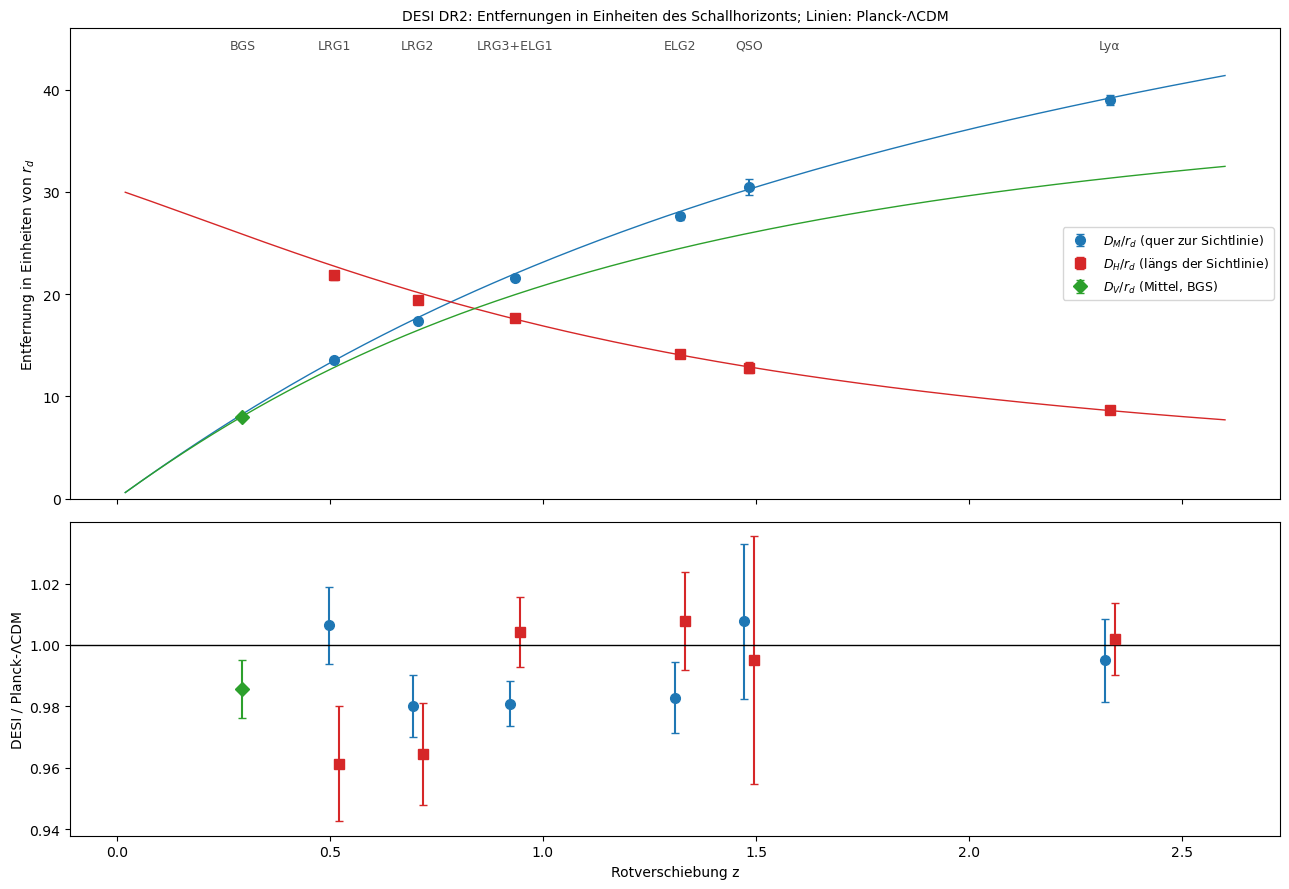

χ² gegen Planck-ΛCDM: 30.0 bei 13 Werten
BGS        z = 0.295: DV/r_d = 7.942 ± 0.076 (0.986)
LRG1       z = 0.510: DM/r_d = 13.588 ± 0.168 (1.006), DH/r_d = 21.863 ± 0.429 (0.961), Korrelation -0.45
LRG2       z = 0.706: DM/r_d = 17.351 ± 0.180 (0.980), DH/r_d = 19.455 ± 0.334 (0.965), Korrelation -0.40
LRG3+ELG1  z = 0.934: DM/r_d = 21.576 ± 0.162 (0.981), DH/r_d = 17.641 ± 0.201 (1.004), Korrelation -0.35
ELG2       z = 1.321: DM/r_d = 27.601 ± 0.325 (0.983), DH/r_d = 14.176 ± 0.225 (1.008), Korrelation -0.40
QSO        z = 1.484: DM/r_d = 30.512 ± 0.764 (1.008), DH/r_d = 12.817 ± 0.518 (0.995), Korrelation -0.49
Lyα        z = 2.330: DH/r_d = 8.632 ± 0.101 (1.002), DM/r_d = 38.989 ± 0.532 (0.995), Korrelation -0.43


In [3]:
pred = bao_model(C_PLANCK)
zz = np.linspace(0.02, 2.6, 300)
DMp, DHp, DVp = distances(C_PLANCK, zz)
style = {"DM_over_rs": ("C0", "o", r"$D_M/r_d$ (quer zur Sichtlinie)", DMp, -0.012),
         "DH_over_rs": ("C3", "s", r"$D_H/r_d$ (längs der Sichtlinie)", DHp, 0.012),
         "DV_over_rs": ("C2", "D", r"$D_V/r_d$ (Mittel, BGS)", DVp, 0.0)}
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw=dict(height_ratios=[3, 2]))
for k, (col, mk, lab, curve, dz) in style.items():
    m = KIND == k
    ax.errorbar(Z_BAO[m], Y_BAO[m], yerr=ERR_BAO[m], fmt=mk, color=col, ms=7, capsize=3, label=lab)
    ax.plot(zz, curve / C_PLANCK["rd"], color=col, lw=1)
    ax2.errorbar(Z_BAO[m] + dz, Y_BAO[m] / pred[m], yerr=ERR_BAO[m] / pred[m], fmt=mk, color=col, ms=7, capsize=3)
for z0, name in TRACERS.items():
    ax.text(z0, 44, name, ha="center", fontsize=9, color="0.3")
ax.set_ylim(0, 46)
ax.set_ylabel("Entfernung in Einheiten von $r_d$")
ax.set_title("DESI DR2: Entfernungen in Einheiten des Schallhorizonts; Linien: Planck-ΛCDM", fontsize=10)
ax.legend(fontsize=9, loc="center right")
ax2.axhline(1, color="k", lw=1)
ax2.set_xlabel("Rotverschiebung z")
ax2.set_ylabel("DESI / Planck-ΛCDM")
plt.tight_layout()
plt.show()

r = Y_BAO - pred
print(f"χ² gegen Planck-ΛCDM: {r @ IC_BAO @ r:.1f} bei {len(Y_BAO)} Werten")
for z0, name in TRACERS.items():
    idx = np.where(Z_BAO == z0)[0]
    txt = ", ".join(f"{KIND[i][:2]}/r_d = {Y_BAO[i]:.3f} ± {ERR_BAO[i]:.3f} ({Y_BAO[i] / pred[i]:.3f})" for i in idx)
    if len(idx) == 2:
        txt += f", Korrelation {COV_BAO[idx[0], idx[1]] / (ERR_BAO[idx[0]] * ERR_BAO[idx[1]]):+.2f}"
    print(f"{name:10s} z = {z0:5.3f}: {txt}")

* Oben die 13 Messwerte von DESI in Einheiten von $r_d$: blau $D_M$ quer zur Sichtlinie, rot $D_H$ längs der Sichtlinie, grün $D_V$ für die hellen Galaxien (BGS), mit den Kurven von Planck-ΛCDM. Unten jeder Wert geteilt durch die Vorhersage von Planck. Die Fehler liegen zwischen 0.7 % ($D_M$ bei z = 0.934) und 4 % ($D_H$ der Quasare).
* Die meisten Punkte liegen 1 bis 4 % unter Planck. Am weitesten weichen $D_H$ bei z = 0.51 und 0.71 ab (0.961 und 0.965), und auch $D_V$ bei z = 0.295 (0.986) und $D_M$ bei z = 0.71 bis 1.3 (0.980 bis 0.983). Bei z = 2.33 (Lyman-α) stimmt Planck auf 0.5 %. Insgesamt ist χ² = 30.0 bei 13 Werten: Planck-ΛCDM passt nicht gut, obwohl kein einzelner Punkt mehr als 2.6σ abweicht ($D_M$ bei z = 0.934). Die Fehler von $D_M$ und $D_H$ derselben Stichprobe sind mit −0.35 bis −0.49 korreliert.
* Zur Vorhersage: $D_H/r_d = c/(H r_d)$ fällt mit z, von 22 bei z = 0.5 auf 8.6 bei z = 2.33, weil das Universum früher schneller expandierte. $D_M$ wächst dagegen, und bei z ≈ 0.8 kreuzen sich die beiden.

[↑ Zurück zur Landkarte](#landkarte)

#### **Reduktion**

<a id="exp-2"></a>

##### *2. Alcock-Paczynski: die Form ohne Maßstab*

Wie viel Materie verlangt allein das Verhältnis von Breite zu Tiefe des BAO-Buckels, ganz ohne $r_d$ und $H_0$? Vorher vorhersagen: Wird $F_\text{AP} = D_M/D_H$ bei mehr Materie größer oder kleiner?

Für die sechs Stichproben mit getrennten $D_M$ und $D_H$ bildet der Code $F_\text{AP} = D_M/D_H$ (Theorie, Abschnitt 3). Den Fehler pflanzt er mit der 2 × 2-Kovarianz jeder Stichprobe fort. Dann sucht er das $\Omega_m$ eines flachen ΛCDM-Modells, das alle sechs am besten trifft. Im Bild steht $F_\text{AP}/z$, damit der starke Anstieg mit z nicht alles überdeckt, mit Kurven für drei Werte von $\Omega_m$.

**Hintergrund & Fachbegriffe:**
- **Fehlerfortpflanzung eines Verhältnisses:** $(\sigma_F/F)^2 = (\sigma_M/D_M)^2 + (\sigma_H/D_H)^2 - 2\,\mathrm{cov}(D_M, D_H)/(D_M D_H)$; die negative Korrelation vergrößert den Fehler des Verhältnisses.
- **Form der Expansionsgeschichte:** wie schnell $H(z)$ mit z wächst, unabhängig von seinem heutigen Wert.

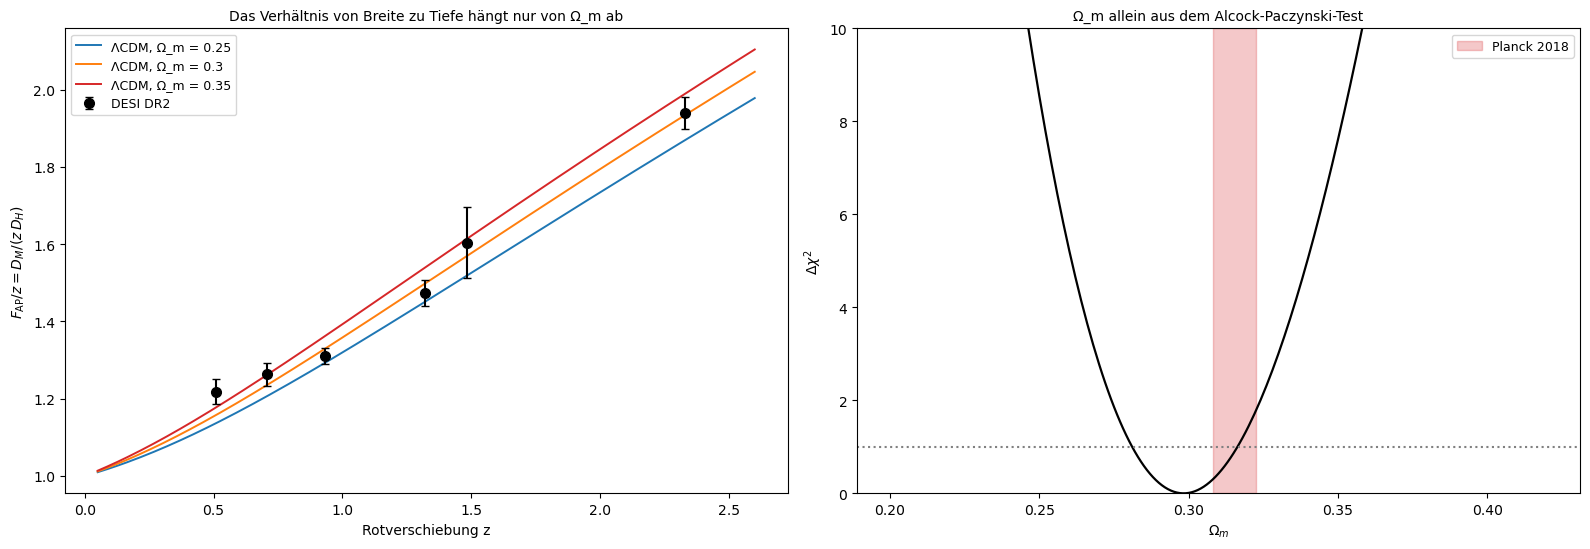

z = 0.510: F_AP = 0.6215 ± 0.0171 (2.8 %)
z = 0.706: F_AP = 0.8918 ± 0.0208 (2.3 %)
z = 0.934: F_AP = 1.2230 ± 0.0192 (1.6 %)
z = 1.321: F_AP = 1.9470 ± 0.0451 (2.3 %)
z = 1.484: F_AP = 2.3806 ± 0.1359 (5.7 %)
z = 2.330: F_AP = 4.5170 ± 0.0969 (2.1 %)
Ω_m = 0.298 ± 0.017, χ² = 5.86 bei 6 Werten und 1 Parameter


In [4]:
pairs = [(i, j) for i in range(len(Z_BAO)) for j in range(len(Z_BAO))
         if Z_BAO[i] == Z_BAO[j] and KIND[i] == "DM_over_rs" and KIND[j] == "DH_over_rs"]
z_ap = np.array([Z_BAO[i] for i, _ in pairs])
F_AP = np.array([Y_BAO[i] / Y_BAO[j] for i, j in pairs])
F_ERR = F_AP * np.array([np.sqrt(COV_BAO[i, i] / Y_BAO[i] ** 2 + COV_BAO[j, j] / Y_BAO[j] ** 2
                                 - 2 * COV_BAO[i, j] / (Y_BAO[i] * Y_BAO[j])) for i, j in pairs])


def f_ap(Om, z):
    DM, DH, _ = distances(cosmo(0.7, 0.0224, Om * 0.49 - OMEGA_NU), z)
    return DM / DH


oms = np.linspace(0.20, 0.42, 221)
chi_ap = np.array([np.sum(((F_AP - f_ap(o, z_ap)) / F_ERR) ** 2) for o in oms])
OM_AP = oms[np.argmin(chi_ap)]
inside = oms[chi_ap - chi_ap.min() <= 1]
OM_AP_ERR = (inside.max() - inside.min()) / 2

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
zz = np.linspace(0.05, 2.6, 200)
for o, col in [(0.25, "C0"), (0.30, "C1"), (0.35, "C3")]:
    ax.plot(zz, f_ap(o, zz) / zz, color=col, lw=1.4, label=f"ΛCDM, Ω_m = {o}")
ax.errorbar(z_ap, F_AP / z_ap, yerr=F_ERR / z_ap, fmt="ko", ms=7, capsize=3, label="DESI DR2")
ax.set_xlabel("Rotverschiebung z")
ax.set_ylabel(r"$F_\mathrm{AP}/z = D_M/(z\,D_H)$")
ax.set_title("Das Verhältnis von Breite zu Tiefe hängt nur von Ω_m ab", fontsize=10)
ax.legend(fontsize=9)
ax2.plot(oms, chi_ap - chi_ap.min(), color="k", lw=1.6)
ax2.axhline(1, color="0.5", ls=":")
ax2.axvspan(PLANCK["Om"] - 0.0073, PLANCK["Om"] + 0.0073, color="C3", alpha=0.25, label="Planck 2018")
ax2.set_ylim(0, 10)
ax2.set_xlabel(r"$\Omega_m$")
ax2.set_ylabel(r"$\Delta\chi^2$")
ax2.set_title("Ω_m allein aus dem Alcock-Paczynski-Test", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

for zi, f, e in zip(z_ap, F_AP, F_ERR):
    print(f"z = {zi:5.3f}: F_AP = {f:.4f} ± {e:.4f} ({100 * e / f:.1f} %)")
print(f"Ω_m = {OM_AP:.3f} ± {OM_AP_ERR:.3f}, χ² = {chi_ap.min():.2f} bei {len(F_AP)} Werten und 1 Parameter")

* Links $F_\text{AP}/z = D_M/(z\,D_H)$ für die sechs Stichproben mit den Kurven von ΛCDM für drei Werte von $\Omega_m$; rechts Δχ² als Funktion von $\Omega_m$, rot das Band von Planck. Die Verhältnisse sind auf 1.6 bis 5.7 % genau, am besten bei z = 0.934 (1.6 %).
* Allein aus der Form des Buckels folgt $\Omega_m = 0.298 \pm 0.017$ mit χ² = 5.86 bei 5 Freiheitsgraden. Das ist ohne Lineal und ohne $H_0$ gemessen, aber nur halb so genau wie mit allen 13 Werten (Schritt 4). Planck (0.315) liegt 1σ entfernt.
* Zur Vorhersage: Mit mehr Materie wird $F_\text{AP}$ größer. Mehr Materie lässt $H(z)$ mit z schneller wachsen, $D_H$ wird bei hohem z kleiner, und $D_M$ als Integral über frühere Werte von $1/H$ reagiert langsamer.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-3"></a>

##### *3. BAO und Supernovae im selben Diagramm*

Passen die Entfernungen aus den BAO und aus den Supernovae zusammen, wenn man beide mit ihrem üblichen Maßstab in Mpc umrechnet? Vorher vorhersagen: Um wie viel Prozent müssten die beiden Leitern auseinanderliegen, wenn die Hubble-Spannung (67.4 gegen 73) ein reiner Maßstabsfehler ist?

Der Code rechnet beide Messungen in die Entfernung $D_M$ in Mpc um:
- **BAO:** mit $r_d$ = 147.09 Mpc von Planck. $D_H$ und $D_V$ werden genauso umgerechnet und durch das Bezugsmodell geteilt.
- **Supernovae:** mit der absoluten Helligkeit $M_B = -19.249$ aus den Cepheiden ([Das Hubble-Diagramm](https://github.com/deltorobarba/science/blob/main/astro/cosmology_hubblediagram.ipynb)), $D_M = 10^{(m_B - M_B - 25)/5}/(1 + z_\text{hel})$ Mpc, gemittelt in Bins.

Beide Entfernungen teilt er durch die von Planck-ΛCDM. Die waagrechte Linie bei $67.36/73.04$ zeigt, wo eine Leiter mit H₀ = 73 und der Form von Planck läge.

**Hintergrund & Fachbegriffe:**
- **Zwei Leitern:** Die Supernovae sind an Cepheiden in nahen Galaxien geeicht (Maßstab $M_B$), die BAO an der Physik vor der Rekombination (Maßstab $r_d$). Die Form der Kurve, $D(z)$ bis auf einen Faktor, messen beide unabhängig von ihrem Maßstab.
- **Gewichtetes Mittel im Bin:** $\bar x = \sum x_i/\sigma_i^2 / \sum 1/\sigma_i^2$ mit den Diagonalfehlern; die Korrelationen der Supernovae sind dabei vernachlässigt.

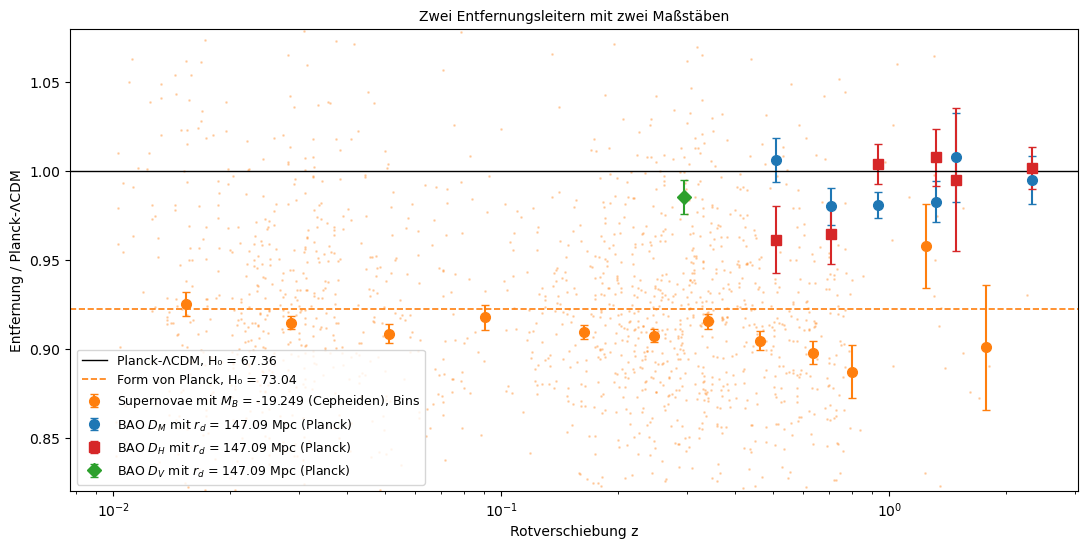

Supernovae, z > 0.1: mittleres Verhältnis 0.9083; BAO: 0.9887
Verhältnis der beiden Leitern: 1.0885; 67.36/73.04 = 0.9222


In [5]:
dm_sn = 10 ** ((M_SN - M_B_CEPHEID - 25) / 5) / (1 + ZHEL_SN)
ratio_sn = dm_sn / distances(C_PLANCK, Z_SN)[0]
sig_sn = np.log(10) / 5 * np.sqrt(np.diag(COV_SN)) * ratio_sn
edges = np.array([0.01, 0.02, 0.04, 0.07, 0.12, 0.2, 0.3, 0.4, 0.55, 0.75, 1.0, 1.5, 2.3])
k = np.digitize(Z_SN, edges) - 1
zb, rb, eb = [], [], []
for i in range(len(edges) - 1):
    m = k == i
    if m.sum() >= 3:
        w = 1 / sig_sn[m] ** 2
        zb.append(np.average(Z_SN[m], weights=w))
        rb.append(np.average(ratio_sn[m], weights=w))
        eb.append(1 / np.sqrt(w.sum()))
zb, rb, eb = map(np.array, (zb, rb, eb))
ratio_bao = Y_BAO / pred

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(Z_SN, ratio_sn, ".", ms=2, color="C1", alpha=0.25)
ax.errorbar(zb, rb, yerr=eb, fmt="o", color="C1", ms=7, capsize=3, label=f"Supernovae mit $M_B$ = {M_B_CEPHEID} (Cepheiden), Bins")
for kk, (col, mk, lab) in {"DM_over_rs": ("C0", "o", r"BAO $D_M$"), "DH_over_rs": ("C3", "s", r"BAO $D_H$"),
                           "DV_over_rs": ("C2", "D", r"BAO $D_V$")}.items():
    m = KIND == kk
    ax.errorbar(Z_BAO[m], ratio_bao[m], yerr=ERR_BAO[m] / pred[m], fmt=mk, color=col, ms=7, capsize=3,
                label=lab + f" mit $r_d$ = {PLANCK['rd']} Mpc (Planck)")
ax.axhline(1, color="k", lw=1, label="Planck-ΛCDM, H₀ = 67.36")
ax.axhline(PLANCK["H0"][0] / H0_SH0ES[0], color="C1", ls="--", lw=1.2, label="Form von Planck, H₀ = 73.04")
ax.set_xscale("log")
ax.set_ylim(0.82, 1.08)
ax.set_xlabel("Rotverschiebung z")
ax.set_ylabel("Entfernung / Planck-ΛCDM")
ax.set_title("Zwei Entfernungsleitern mit zwei Maßstäben", fontsize=10)
ax.legend(fontsize=9, loc="lower left")
plt.show()

m = (zb > 0.1)
print(f"Supernovae, z > 0.1: mittleres Verhältnis {np.average(rb[m], weights=1 / eb[m] ** 2):.4f}; "
      f"BAO: {np.average(ratio_bao, weights=(pred / ERR_BAO) ** 2):.4f}")
print(f"Verhältnis der beiden Leitern: {np.average(ratio_bao, weights=(pred / ERR_BAO) ** 2) / np.average(rb[m], weights=1 / eb[m] ** 2):.4f}; "
      f"67.36/73.04 = {PLANCK['H0'][0] / H0_SH0ES[0]:.4f}")

* Alle Entfernungen sind durch Planck-ΛCDM geteilt: orange die Supernovae, geeicht mit $M_B$ aus den Cepheiden (blasse Punkte einzeln, große Punkte in Bins), blau, rot und grün die BAO, geeicht mit $r_d$ = 147.09 Mpc von Planck. Die orange gestrichelte Linie zeigt, wo eine Leiter mit H₀ = 73 und der Form von Planck läge.
* Die beiden Leitern liegen um 8.9 % auseinander. Die Supernovae liegen bei z > 0.1 im Mittel bei 0.908, die BAO bei 0.989 (gewichtetes Mittel aller 13 Werte). Innerhalb jeder Leiter ist die Form fast flach: Die Supernovae liegen von z = 0.01 bis 0.6 zwischen 0.90 und 0.93, die BAO von z = 0.3 bis 2.3 zwischen 0.96 und 1.01.
* Zur Vorhersage: 67.36/73.04 = 0.922, also 7.8 %. Gemessen sind 8.9 %, weil die Supernovae zusätzlich ein etwas größeres $\Omega_m$ wollen als Planck (Schritt 9). Die Hubble-Spannung ist also im Kern ein Unterschied der Maßstäbe. Entweder sind die Supernovae um 0.18 mag heller, als die Cepheiden sagen ($M_B$ ≈ −19.43 statt −19.25), oder $r_d$ ist etwa 8 % kleiner, als die Physik vor der Rekombination vorhersagt (135 statt 147 Mpc).

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung**

<a id="exp-4"></a>

##### *4. Ω_m und h·r_d nur aus den BAO*

Welche zwei Zahlen legen die BAO allein fest, und wie genau? Vorher vorhersagen: Warum sind $\Omega_m$ und $h\,r_d$ negativ korreliert?

Nach Theorie, Abschnitt 2, hängen alle 13 Messwerte in flachem ΛCDM nur von $\Omega_m$ und $h\,r_d$ ab. Der Code rechnet χ² auf einem Gitter dieser beiden Größen. Dabei setzt er h = 0.7 fest und $r_d = (h\,r_d)/h$; welches h man wählt, ist gleich. Er sucht das Minimum, die Fehler aus der Krümmung, und zeichnet die 68- und 95-%-Konturen. Zum Vergleich stehen der Punkt von Planck und das Band aus dem Alcock-Paczynski-Test (Schritt 2) im Bild.

**Hintergrund & Fachbegriffe:**
- **Konturen:** Linien gleicher Δχ² über dem Minimum; für zwei Parameter umschließen Δχ² = 2.30 und 6.18 die Bereiche mit 68 und 95 % Wahrscheinlichkeit.
- **Entartung:** Mehr Materie macht die Expansion früher schneller und alle Entfernungen kleiner; ein größeres $c/(H_0 r_d)$ gleicht das aus.

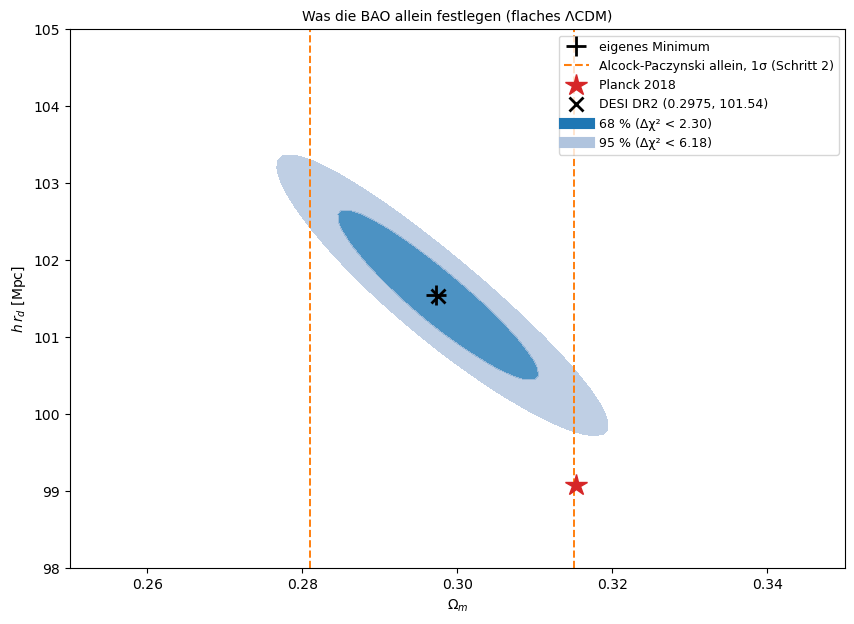

Ω_m = 0.2972 ± 0.0086, h r_d = 101.55 ± 0.74 Mpc, Korrelation -0.92, χ² = 10.28 bei 13 − 2 Freiheitsgraden
DESI DR2: Ω_m = 0.2975 ± 0.0086, h r_d = 101.54 ± 0.73 Mpc, Korrelation −0.92; Planck: h r_d = 99.08 Mpc


In [6]:
def chi2_om_hrd(Om, hrd):
    c = cosmo(0.7, 0.0224, Om * 0.49 - OMEGA_NU)
    return chi2_bao(dict(c, rd=hrd / 0.7))


r4 = optimize.minimize(lambda q: chi2_om_hrd(*q), [0.30, 101.5], method="Nelder-Mead", options=dict(xatol=1e-8, fatol=1e-10))
eps = np.array([1e-4, 1e-2])
Hq = np.array([[(chi2_om_hrd(*(r4.x + np.eye(2)[i] * eps[i] + np.eye(2)[j] * eps[j]))
                 - chi2_om_hrd(*(r4.x + np.eye(2)[i] * eps[i] - np.eye(2)[j] * eps[j]))
                 - chi2_om_hrd(*(r4.x - np.eye(2)[i] * eps[i] + np.eye(2)[j] * eps[j]))
                 + chi2_om_hrd(*(r4.x - np.eye(2)[i] * eps[i] - np.eye(2)[j] * eps[j]))) / (4 * eps[i] * eps[j])
                for j in range(2)] for i in range(2)])
BAO2 = (r4.x, np.linalg.inv(Hq / 2))                     # (Ω_m, h r_d) und Kovarianz
e4 = np.sqrt(np.diag(BAO2[1]))
om_g, hrd_g = np.linspace(0.25, 0.35, 81), np.linspace(98, 105, 71)
grid = np.array([[chi2_om_hrd(o, x) for o in om_g] for x in hrd_g])

fig, ax = plt.subplots(figsize=(10, 7))
cs = ax.contourf(om_g, hrd_g, grid - r4.fun, levels=[0, 2.30, 6.18], colors=["C0", "lightsteelblue"], alpha=0.8)
ax.plot(*r4.x, "k+", ms=14, mew=2, label="eigenes Minimum")
for x in (OM_AP - OM_AP_ERR, OM_AP + OM_AP_ERR):
    ax.axvline(x, color="C1", ls="--", lw=1.4)
ax.plot([], [], color="C1", ls="--", label="Alcock-Paczynski allein, 1σ (Schritt 2)")
ax.plot(PLANCK["Om"], PLANCK["h"] * PLANCK["rd"], "*", color="C3", ms=16, label="Planck 2018")
ax.plot(0.2975, 101.54, "x", color="k", ms=10, mew=2, label="DESI DR2 (0.2975, 101.54)")
ax.plot([], [], color="C0", lw=8, label="68 % (Δχ² < 2.30)")
ax.plot([], [], color="lightsteelblue", lw=8, label="95 % (Δχ² < 6.18)")
ax.set_xlabel(r"$\Omega_m$")
ax.set_ylabel(r"$h\,r_d$ [Mpc]")
ax.set_title("Was die BAO allein festlegen (flaches ΛCDM)", fontsize=10)
ax.legend(fontsize=9)
plt.show()

rho = BAO2[1][0, 1] / (e4[0] * e4[1])
print(f"Ω_m = {r4.x[0]:.4f} ± {e4[0]:.4f}, h r_d = {r4.x[1]:.2f} ± {e4[1]:.2f} Mpc, Korrelation {rho:.2f}, "
      f"χ² = {r4.fun:.2f} bei {len(Y_BAO)} − 2 Freiheitsgraden")
print(f"DESI DR2: Ω_m = 0.2975 ± 0.0086, h r_d = 101.54 ± 0.73 Mpc, Korrelation −0.92; Planck: h r_d = {PLANCK['h'] * PLANCK['rd']:.2f} Mpc")

* Die Bereiche, die die BAO in der Ebene von $\Omega_m$ und $h\,r_d$ erlauben (68 und 95 %), mit dem eigenen Minimum (+), dem Wert von DESI (×), dem Band aus dem Alcock-Paczynski-Test (gestrichelt) und dem Punkt von Planck (Stern). Die Ellipse ist schmal und gekippt: Die beiden Größen sind zu −0.92 korreliert.
* Ergebnis: $\Omega_m = 0.2972 \pm 0.0086$ und $h\,r_d = (101.55 \pm 0.74)$ Mpc mit χ² = 10.28 bei 11 Freiheitsgraden. DESI DR2 gibt 0.2975 ± 0.0086 und 101.54 ± 0.73 an; die eigene Rechnung trifft beide auf 0.04σ. Planck (Ω_m = 0.315, $h\,r_d$ = 99.08 Mpc) liegt knapp außerhalb der 95-%-Kontur.
* Zur Vorhersage: Mehr Materie macht alle Entfernungen bei z ≈ 0.5 bis 2 kleiner. Damit die gemessenen $D/r_d$ gleich bleiben, muss $c/(H_0 r_d)$ größer werden, also $h\,r_d$ kleiner. Deshalb fällt die Ellipse nach rechts ab.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-5"></a>

##### *5. Der Schallhorizont r_d*

Wie lang ist das Lineal, und wovon hängt seine Länge ab? Vorher vorhersagen: Ist $r_d$ größer oder kleiner als der Schallhorizont $r_\star$ der Hintergrundstrahlung?

Der Code rechnet mit den Dichten von Planck den Schallhorizont als Integral (Theorie, Abschnitt 1), einmal bis $z_\star$ und einmal bis $z_d$. Dazu kommen drei Varianten:
- $r_d$ mit der ungeeichten Näherung für $z_d$,
- die Näherungsformel von Aubourg et al. (2015, Gl. 16), die an viele Rechnungen mit einem Boltzmann-Code angepasst ist,
- $r_d$ auf einem Gitter von $\omega_{cb}$ für drei Werte von $\omega_b$.

Links steht der Schallhorizont nahe der Rekombination, rechts $r_d$ als Funktion der Dichten.

**Hintergrund & Fachbegriffe:**
- **Drag-Epoche $z_d$:** der Zeitpunkt, ab dem die Baryonen den Druck der Photonen nicht mehr spüren; definiert über die optische Tiefe der Baryonen für Thomson-Streuung, die dort 1 wird.
- **Aubourg-Formel:** $r_d = 55.154\,e^{-72.3(\omega_\nu + 0.0006)^2} / (\omega_{cb}^{0.25351}\,\omega_b^{0.12807})$ Mpc, auf 0.02 % genau für $N_\text{eff} = 3.046$.

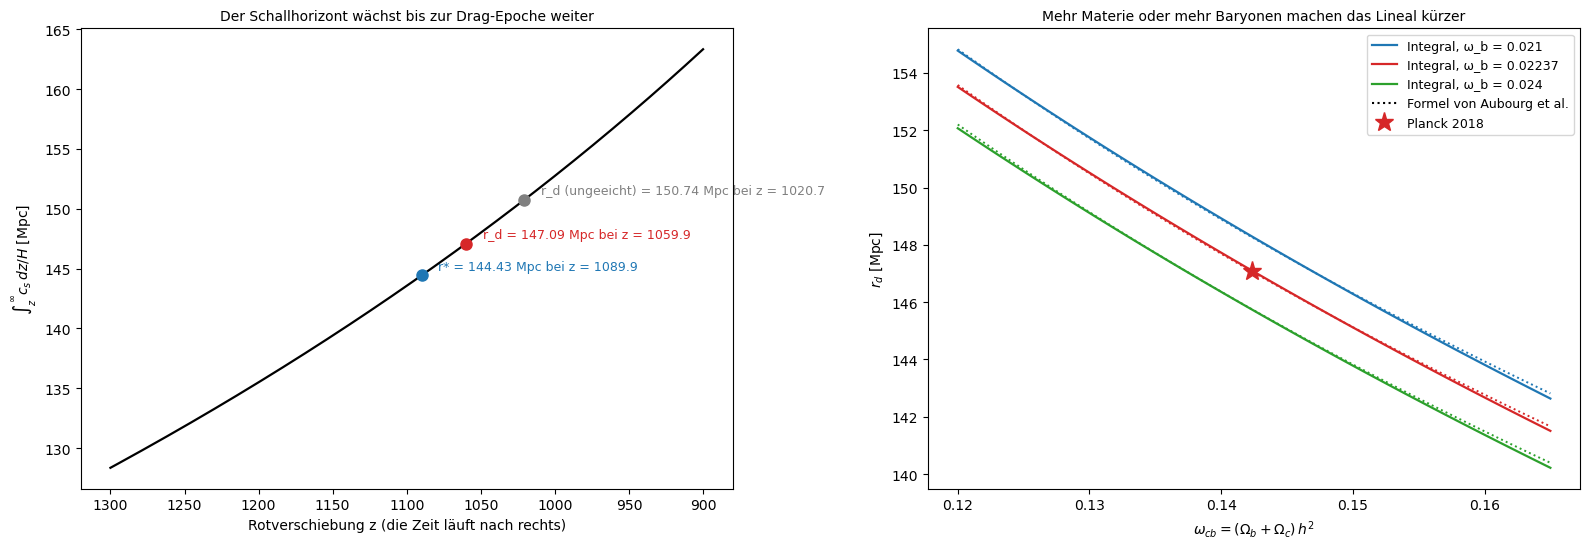

z* = 1089.92, z_d = 1059.94 (Näherung ungeeicht 1020.7); r* = 144.43 Mpc, r_d = 147.09 Mpc (+1.8 %)
r_d ungeeicht 150.74 Mpc (+2.5 %), Aubourg 147.06 Mpc, Planck 147.09
Empfindlichkeit: d ln r_d / d ln ω_cb = -0.257, d ln r_d / d ln ω_b = -0.130 (Aubourg: −0.254, −0.128)


In [7]:
def aubourg(wb, wcb, wnu=OMEGA_NU):
    return 55.154 * np.exp(-72.3 * (wnu + 0.0006) ** 2) / (wcb**0.25351 * wb**0.12807)


c5 = C_PLANCK
zd_raw = z_drag(PLANCK["wb"], WM_PLANCK)
rd_raw = np.interp(np.log1p(zd_raw), X, c5["rs_above"])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
zz = np.linspace(900, 1300, 400)
ax.plot(zz, np.interp(np.log1p(zz), X, c5["rs_above"]), color="k", lw=1.6)
for zv, rv, lab, col in [(c5["zs"], c5["rstar"], "r*", "C0"), (c5["zd"], c5["rd"], "r_d", "C3"), (zd_raw, rd_raw, "r_d (ungeeicht)", "0.5")]:
    ax.plot(zv, rv, "o", color=col, ms=8)
    ax.annotate(f"{lab} = {rv:.2f} Mpc bei z = {zv:.1f}", (zv, rv), xytext=(12, 4), textcoords="offset points", fontsize=9, color=col)
ax.invert_xaxis()
ax.set_xlabel("Rotverschiebung z (die Zeit läuft nach rechts)")
ax.set_ylabel(r"$\int_z^\infty c_s\,dz/H$ [Mpc]")
ax.set_title("Der Schallhorizont wächst bis zur Drag-Epoche weiter", fontsize=10)
wcbs = np.linspace(0.12, 0.165, 46)
for wb_, col in [(0.0210, "C0"), (PLANCK["wb"], "C3"), (0.0240, "C2")]:
    ax2.plot(wcbs, [cosmo(PLANCK["h"], wb_, x)["rd"] for x in wcbs], color=col, lw=1.6, label=f"Integral, ω_b = {wb_}")
    ax2.plot(wcbs, aubourg(wb_, wcbs), color=col, ls=":", lw=1.4)
ax2.plot([], [], color="k", ls=":", label="Formel von Aubourg et al.")
ax2.plot(PLANCK["wb"] + PLANCK["wc"], PLANCK["rd"], "*", color="C3", ms=14, label="Planck 2018")
ax2.set_xlabel(r"$\omega_{cb} = (\Omega_b + \Omega_c)\,h^2$")
ax2.set_ylabel(r"$r_d$ [Mpc]")
ax2.set_title("Mehr Materie oder mehr Baryonen machen das Lineal kürzer", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

wcbP = PLANCK["wb"] + PLANCK["wc"]
d = 1e-3
s_cb = (np.log(cosmo(PLANCK["h"], PLANCK["wb"], wcbP * (1 + d))["rd"]) - np.log(cosmo(PLANCK["h"], PLANCK["wb"], wcbP * (1 - d))["rd"])) / (2 * d)
s_b = (np.log(cosmo(PLANCK["h"], PLANCK["wb"] * (1 + d), wcbP)["rd"]) - np.log(cosmo(PLANCK["h"], PLANCK["wb"] * (1 - d), wcbP)["rd"])) / (2 * d)
print(f"z* = {c5['zs']:.2f}, z_d = {c5['zd']:.2f} (Näherung ungeeicht {zd_raw:.1f}); r* = {c5['rstar']:.2f} Mpc, r_d = {c5['rd']:.2f} Mpc "
      f"(+{100 * (c5['rd'] / c5['rstar'] - 1):.1f} %)")
print(f"r_d ungeeicht {rd_raw:.2f} Mpc ({100 * (rd_raw / c5['rd'] - 1):+.1f} %), Aubourg {aubourg(PLANCK['wb'], wcbP):.2f} Mpc, Planck {PLANCK['rd']}")
print(f"Empfindlichkeit: d ln r_d / d ln ω_cb = {s_cb:.3f}, d ln r_d / d ln ω_b = {s_b:.3f} (Aubourg: −0.254, −0.128)")

* Links der Schallhorizont, aufsummiert von z = ∞ bis z, nahe der Rekombination: Er ist bei $z_\star$ = 1089.9 auf $r_\star$ = 144.43 Mpc gewachsen und bis $z_d$ = 1059.9 auf $r_d$ = 147.09 Mpc, 1.8 % mehr. Grau der Wert mit der ungeeichten Näherung für $z_d$ (1020.7): 150.74 Mpc, 2.5 % zu groß.
* Rechts $r_d$ als Funktion von $\omega_{cb}$ für drei Werte von $\omega_b$, durchgezogen das eigene Integral, gepunktet die Formel von Aubourg et al. Die beiden stimmen beim Planck-Punkt auf 0.02 % (147.09 gegen 147.06 Mpc) und am Rand des Gitters auf 0.2 %. Der Stern ist Planck.
* Die Empfindlichkeiten sind $d\ln r_d/d\ln\omega_{cb} = -0.257$ und $d\ln r_d/d\ln\omega_b = -0.130$, fast genau die Exponenten von Aubourg (−0.254 und −0.128). Zur Vorhersage: $r_d$ ist größer als $r_\star$, weil die Baryonen nach der Entkopplung der Photonen noch etwa 30 Rotverschiebungseinheiten lang mitgeschleppt werden.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-6"></a>

##### *6. Die inverse Entfernungsleiter*

Welche Hubble-Konstante folgt aus den BAO, wenn man $r_d$ aus der Physik des frühen Universums nimmt statt aus Cepheiden? Vorher vorhersagen: Liegt das Ergebnis näher an 67 oder an 73?

Der Code passt h, $\omega_b$ und $\omega_{cb}$ an zwei Kombinationen an (Theorie, Abschnitt 4):
- **BAO + BBN:** die 13 Messwerte von DESI und $\omega_b = 0.02218 \pm 0.00055$ aus dem Deuterium.
- **BAO + BBN + θ*:** zusätzlich der Winkel 100 $\theta_\star$ = 1.04110 ± 0.00053 aus der Hintergrundstrahlung.

Die Fehler kommen aus der Krümmung von χ². Im Bild stehen die Ellipsen in der Ebene von $\Omega_m$ und $H_0$, mit dem Band von SH0ES und dem Punkt von Planck.

**Hintergrund & Fachbegriffe:**
- **Nukleosynthese (BBN):** Die ersten Atomkerne bilden sich in den ersten Minuten. Wie viel Deuterium übrig bleibt, hängt empfindlich davon ab, wie viele Baryonen pro Photon es gibt; D/H wird in Gaswolken vor fernen Quasaren gemessen.
- **Warum θ* hilft:** $\theta_\star$ legt eine Kombination von $\Omega_m$ und $h$ fest (in [Die akustischen Peaks](https://github.com/deltorobarba/science/blob/main/astro/cosmology_cmbpeaks.ipynb) die Linie $\Omega_m h^3 \approx$ konst.). Ihre Richtung kreuzt die der BAO und verkleinert die Ellipse.

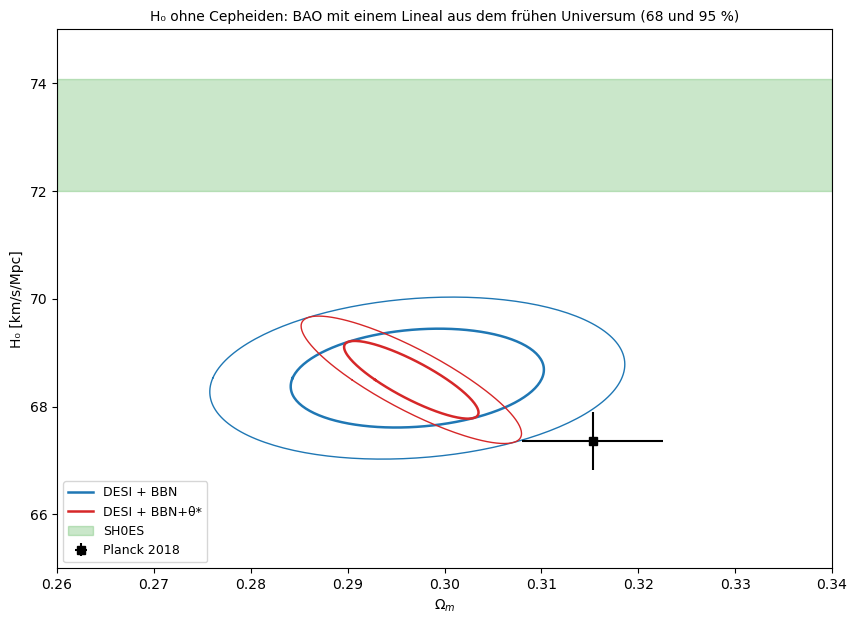

BAO+BBN    : H₀ = 68.53 ± 0.60, Ω_m = 0.2972 ± 0.0086, ω_b = 0.02218, r_d = 148.18 Mpc, χ² = 10.28; gegen SH0ES 3.7 σ
BAO+BBN+θ* : H₀ = 68.50 ± 0.48, Ω_m = 0.2966 ± 0.0046, ω_b = 0.02217, r_d = 148.30 Mpc, χ² = 10.29; gegen SH0ES 4.0 σ
DESI DR2: BAO+BBN 68.51 ± 0.58 (Ω_m 0.2977 ± 0.0086); BAO+BBN+θ* 68.45 ± 0.47 (Ω_m 0.2967 ± 0.0045)


In [8]:
FITS = {}
for key, data in [("BAO+BBN", ("BAO", "BBN")), ("BAO+BBN+θ*", ("BAO", "BBN", "THETA"))]:
    r = fit(data)
    cov = covariance(r.x, data)
    FITS[key] = (r, cov, derived(r.x), derived_cov(r.x, cov))
fig, ax = plt.subplots(figsize=(10, 7))
for (key, (r, cov, dv, dcov)), col in zip(FITS.items(), ["C0", "C3"]):
    ellipse(ax, dv[[1, 0]], dcov[np.ix_([1, 0], [1, 0])], col, label=f"DESI + {key[4:]}")
ax.axhspan(H0_SH0ES[0] - H0_SH0ES[1], H0_SH0ES[0] + H0_SH0ES[1], color="C2", alpha=0.25, label="SH0ES")
ax.errorbar(PLANCK["Om"], PLANCK["H0"][0], xerr=0.0073, yerr=PLANCK["H0"][1], fmt="s", color="k", label="Planck 2018")
ax.set_xlabel(r"$\Omega_m$")
ax.set_ylabel("H₀ [km/s/Mpc]")
ax.set_xlim(0.26, 0.34)
ax.set_ylim(65, 75)
ax.set_title("H₀ ohne Cepheiden: BAO mit einem Lineal aus dem frühen Universum (68 und 95 %)", fontsize=10)
ax.legend(fontsize=9)
plt.show()

for key, (r, cov, dv, dcov) in FITS.items():
    e = np.sqrt(np.diag(dcov))
    print(f"{key:11s}: H₀ = {dv[0]:.2f} ± {e[0]:.2f}, Ω_m = {dv[1]:.4f} ± {e[1]:.4f}, ω_b = {r.x[1]:.5f}, "
          f"r_d = {dv[2] / r.x[0]:.2f} Mpc, χ² = {r.fun:.2f}; gegen SH0ES {(H0_SH0ES[0] - dv[0]) / np.hypot(e[0], H0_SH0ES[1]):.1f} σ")
print("DESI DR2: BAO+BBN 68.51 ± 0.58 (Ω_m 0.2977 ± 0.0086); BAO+BBN+θ* 68.45 ± 0.47 (Ω_m 0.2967 ± 0.0045)")

* Die Ellipsen (68 und 95 %) in der Ebene von $\Omega_m$ und H₀: blau BAO mit BBN, rot zusätzlich mit $\theta_\star$, grün das Band von SH0ES, schwarz Planck. Beide Ellipsen liegen weit unter SH0ES und knapp über Planck.
* BAO + BBN gibt H₀ = 68.53 ± 0.60 bei $r_d$ = 148.2 Mpc, mit θ* 68.50 ± 0.48 und $\Omega_m$ = 0.2966 ± 0.0046. DESI DR2 hat 68.51 ± 0.58 und 68.45 ± 0.47. Der Abstand zu SH0ES ist 3.7σ und 4.0σ. Damit ist die Spannung ohne jede Messung der Hintergrundstrahlung da: Eine Leiter, die bei der Nukleosynthese beginnt, kommt nicht auf 73.
* Zur Vorhersage: näher an 67. Mit θ* wird die Ellipse schmaler und kippt, weil θ* eine andere Kombination von $\Omega_m$ und h festlegt als die BAO. H₀ bleibt fast gleich, der Fehler fällt um 20 %.

[↑ Zurück zur Landkarte](#landkarte)

#### **Modell und Fit**

<a id="exp-7"></a>

##### *7. Der Buckel in der Verteilung der Galaxien*

Wie sieht das Lineal in der Verteilung der Materie aus, und wie hängt es von den Baryonen ab? Vorher vorhersagen: Was passiert mit dem Buckel, wenn es fast keine Baryonen gibt?

Der Code rechnet das Leistungsspektrum der Materie mit der Transferfunktion von Eisenstein & Hu (1998) samt Baryonen: $P(k) \propto k^{n_s} T(k)^2$. Daraus wird die Korrelationsfunktion

$$\xi(r) = \frac{1}{2\pi^2}\int k^2 P(k)\, \frac{\sin kr}{kr}\, e^{-k^2\Sigma^2}\,dk ,$$

wobei $\Sigma$ = 6 Mpc das Verwischen durch die Bewegungen der Galaxien nachahmt. Er tut das für drei Dichten der Baryonen bei fester Gesamtdichte $\omega_m$ = 0.143. Links stehen die Spektren geteilt durch eine glatte Kurve, rechts $r^2\xi(r)$.

**Hintergrund & Fachbegriffe:**
- **Korrelationsfunktion $\xi(r)$:** um wie viel häufiger als zufällig man zwei Galaxien im Abstand r findet.
- **Transferfunktion $T(k)$:** wie stark eine anfängliche Schwankung mit Wellenzahl k bis heute gewachsen ist, relativ zu großen Skalen; die Baryonen prägen ihr Wellen mit der Periode $2\pi/r_d$ auf.
- **Fourier-Paar:** Wellen im Spektrum $P(k)$ mit Abstand $\Delta k = 2\pi/r_d$ werden in $\xi(r)$ zu einem einzelnen Buckel bei $r_d$.

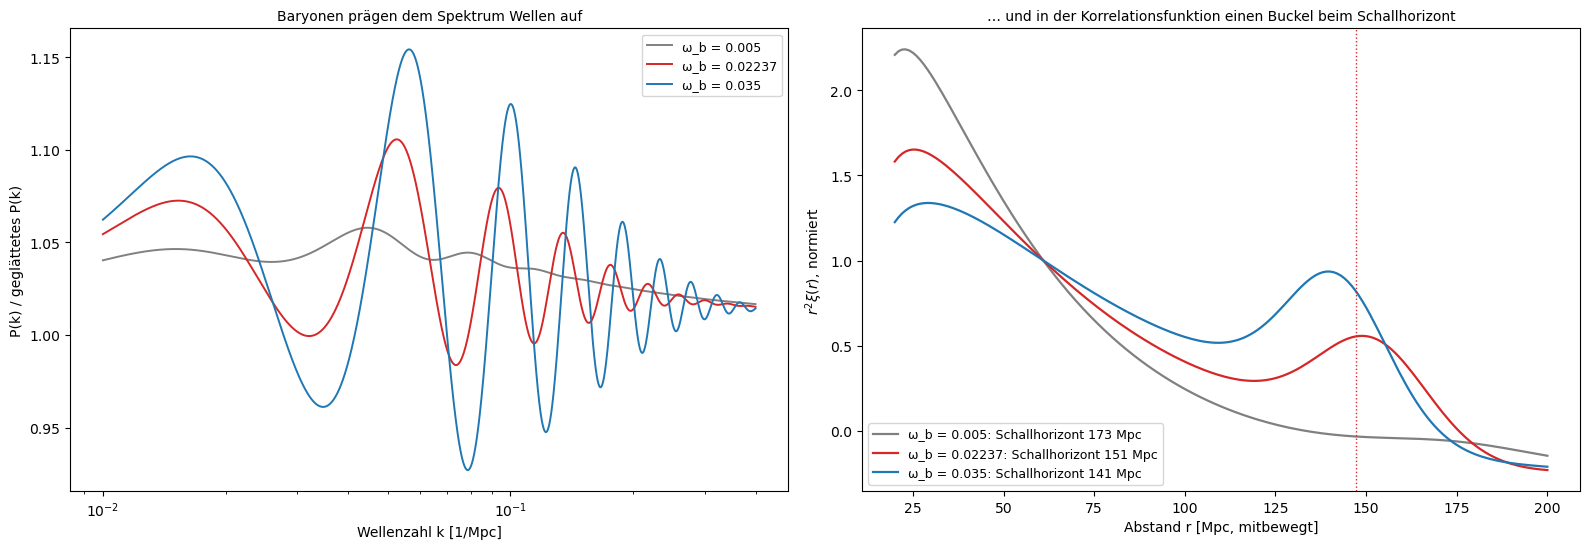

ω_b = 0.005: Schallhorizont nach Eisenstein & Hu 173.0 Mpc, Buckel von r²ξ bei 121 Mpc
ω_b = 0.02237: Schallhorizont nach Eisenstein & Hu 150.9 Mpc, Buckel von r²ξ bei 149 Mpc
ω_b = 0.035: Schallhorizont nach Eisenstein & Hu 141.3 Mpc, Buckel von r²ξ bei 140 Mpc
zum Vergleich r_d aus Schritt 5: 147.09 Mpc


In [9]:
def eh98(k, wb, wm, tcmb=2.7255):
    # Transferfunktion mit Baryonen, Eisenstein & Hu (1998), Gl. 2 bis 24; k in 1/Mpc
    th = tcmb / 2.7
    fb, fc = wb / wm, 1 - wb / wm
    zeq, keq = 2.50e4 * wm * th**-4, 7.46e-2 * wm * th**-2
    zd = z_drag(wb, wm)
    R = lambda z: 31.5 * wb * th**-4 * (z / 1e3) ** -1
    Req, Rd = R(zeq), R(zd)
    s = 2 / (3 * keq) * np.sqrt(6 / Req) * np.log((np.sqrt(1 + Rd) + np.sqrt(Rd + Req)) / (1 + np.sqrt(Req)))
    ksilk = 1.6 * wb**0.52 * wm**0.73 * (1 + (10.4 * wm) ** -0.95)
    q = k / (13.41 * keq)
    a1 = (46.9 * wm) ** 0.670 * (1 + (32.1 * wm) ** -0.532)
    a2 = (12.0 * wm) ** 0.424 * (1 + (45.0 * wm) ** -0.582)
    alpha_c = a1 ** (-fb) * a2 ** (-fb**3)
    bb1, bb2 = 0.944 / (1 + (458 * wm) ** -0.708), (0.395 * wm) ** -0.0266
    beta_c = 1 / (1 + bb1 * (fc**bb2 - 1))

    def T0(a, b):
        L = np.log(np.e + 1.8 * b * q)
        return L / (L + (14.2 / a + 386 / (1 + 69.9 * q**1.08)) * q**2)

    f = 1 / (1 + (k * s / 5.4) ** 4)
    Tc = f * T0(1, beta_c) + (1 - f) * T0(alpha_c, beta_c)
    y = (1 + zeq) / (1 + zd)
    G = y * (-6 * np.sqrt(1 + y) + (2 + 3 * y) * np.log((np.sqrt(1 + y) + 1) / (np.sqrt(1 + y) - 1)))
    alpha_b = 2.07 * keq * s * (1 + Rd) ** -0.75 * G
    beta_b = 0.5 + fb + (3 - 2 * fb) * np.sqrt((17.2 * wm) ** 2 + 1)
    s_t = s / (1 + (8.41 * wm**0.435 / (k * s)) ** 3) ** (1 / 3)
    Tb = (T0(1, 1) / (1 + (k * s / 5.2) ** 2) + alpha_b / (1 + (beta_b / (k * s)) ** 3) * np.exp(-((k / ksilk) ** 1.4))) * np.sinc(k * s_t / np.pi)
    return fb * Tb + fc * Tc, s


k = np.logspace(-4, 1, 20000)
r = np.linspace(20, 200, 181)
damp = np.exp(-(k * 6.0) ** 2)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
EH = {}
for wb_, col in [(0.005, "0.5"), (PLANCK["wb"], "C3"), (0.035, "C0")]:
    T, s = eh98(k, wb_, WM_PLANCK)
    P = k ** 0.9649 * T**2
    smooth = np.exp(ndimage.gaussian_filter1d(np.log(P), 600))
    xi = np.array([np.trapz(k**2 * P * damp * np.sinc(k * rr / np.pi), k) for rr in r]) / (2 * np.pi**2)
    peak = r[r > 120][np.argmax((r**2 * xi)[r > 120])]
    EH[wb_] = (s, peak, r**2 * xi)
    m = (k > 0.01) & (k < 0.4)
    ax.plot(k[m], P[m] / smooth[m], color=col, lw=1.4, label=f"ω_b = {wb_}")
    ax2.plot(r, r**2 * xi / np.max(np.abs(r**2 * xi)[r > 60]), color=col, lw=1.6, label=f"ω_b = {wb_}: Schallhorizont {s:.0f} Mpc")
ax.set_xscale("log")
ax.set_xlabel("Wellenzahl k [1/Mpc]")
ax.set_ylabel("P(k) / geglättetes P(k)")
ax.set_title("Baryonen prägen dem Spektrum Wellen auf", fontsize=10)
ax.legend(fontsize=9)
ax2.axvline(PLANCK["rd"], color="C3", ls=":", lw=1)
ax2.set_xlabel("Abstand r [Mpc, mitbewegt]")
ax2.set_ylabel(r"$r^2\xi(r)$, normiert")
ax2.set_title("… und in der Korrelationsfunktion einen Buckel beim Schallhorizont", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

for wb_, (s, peak, w) in EH.items():
    print(f"ω_b = {wb_}: Schallhorizont nach Eisenstein & Hu {s:.1f} Mpc, Buckel von r²ξ bei {peak:.0f} Mpc")
print(f"zum Vergleich r_d aus Schritt 5: {C_PLANCK['rd']:.2f} Mpc")

* Links das Leistungsspektrum der Materie geteilt durch eine geglättete Fassung, für drei Dichten der Baryonen bei gleicher Gesamtdichte: Mit Baryonen schwingt es mit einer Periode von etwa $\Delta k = 2\pi/r_d \approx 0.04$/Mpc. Die Wellen sind umso stärker, je mehr Baryonen es gibt, und werden zu großen k gedämpft (Silk-Dämpfung). Mit ω_b = 0.005 sind sie fast verschwunden.
* Rechts $r^2\xi(r)$: Mit den Baryonen von Planck sitzt der Buckel bei 149 Mpc, mit ω_b = 0.035 bei 140 Mpc. Er liegt jeweils fast genau beim Schallhorizont der Näherung von Eisenstein & Hu (151 und 141 Mpc), die selbst etwa 2.5 % über dem genauen $r_d$ = 147.1 Mpc liegt (Schritt 5). Mit ω_b = 0.005 gibt es keinen Buckel.
* Zur Vorhersage: Fast ohne Baryonen fehlt das Lineal, und die Korrelationsfunktion fällt glatt ab. Mehr Baryonen machen den Buckel höher, aber das Lineal kürzer, weil sie den Schall bremsen.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-8"></a>

##### *8. BAO gegen Hintergrundstrahlung in ΛCDM*

Sagt die Hintergrundstrahlung in ΛCDM dieselben $\Omega_m$ und $h\,r_d$ voraus, die DESI misst? Vorher vorhersagen: Liegt der Punkt der Hintergrundstrahlung auf der Entartungslinie der BAO oder daneben?

Der Code passt ΛCDM einmal nur an die komprimierte CMB-Likelihood an (Theorie, Abschnitt 6). Er rechnet daraus $\Omega_m$ und $h\,r_d$ mit ihrer Kovarianz und vergleicht mit dem Ergebnis der BAO aus Schritt 4:

$$\Delta\chi^2 = \mathbf d^T (C_\text{BAO} + C_\text{CMB})^{-1} \mathbf d$$

für den Abstand $\mathbf d$ der beiden Punkte, mit 2 Freiheitsgraden. Danach passt er beide zusammen an.

**Hintergrund & Fachbegriffe:**
- **Spannung zwischen zwei Messungen:** Liegen zwei unabhängige Messungen derselben Größen weiter auseinander, als ihre Fehler erlauben, gibt Δχ² mit der Summe der Kovarianzen an, wie unwahrscheinlich das ist.
- **Komprimiert gegen voll:** DESI vergleicht mit der vollen CMB-Likelihood und findet 2.3σ; die drei Zahlen der komprimierten Fassung haben etwas größere Fehler für $\Omega_m$.

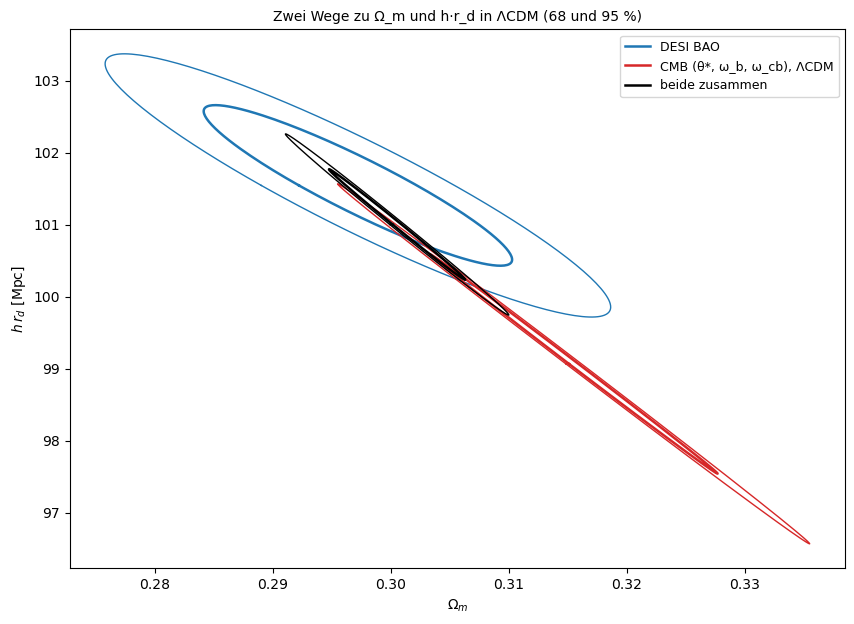

CMB allein: H₀ = 67.26 ± 0.58, Ω_m = 0.3155 ± 0.0080, h r_d = 99.07 ± 1.01
Abstand BAO – CMB: Δχ² = 5.11 bei 2 Freiheitsgraden → 1.8 σ (DESI mit voller CMB: 2.3 σ)
DESI + CMB: H₀ = 68.36 ± 0.30, Ω_m = 0.3005 ± 0.0038, χ² = 15.05 (DESI mit voller CMB: 68.17 ± 0.28, 0.3027 ± 0.0036)


In [10]:
r_cmb = fit(("CMB",))
cov_cmb = covariance(r_cmb.x, ("CMB",))
dv_cmb, dcov_cmb = derived(r_cmb.x), derived_cov(r_cmb.x, cov_cmb)
CMB2 = (dv_cmb[1:], dcov_cmb[1:, 1:])                     # (Ω_m, h r_d)
d = BAO2[0] - CMB2[0]
T_CHI2 = d @ np.linalg.inv(BAO2[1] + CMB2[1]) @ d
r_bc = fit(("BAO", "CMB"))
cov_bc = covariance(r_bc.x, ("BAO", "CMB"))
dv_bc, dcov_bc = derived(r_bc.x), derived_cov(r_bc.x, cov_bc)

fig, ax = plt.subplots(figsize=(10, 7))
ellipse(ax, BAO2[0], BAO2[1], "C0", label="DESI BAO")
ellipse(ax, CMB2[0], CMB2[1], "C3", label="CMB (θ*, ω_b, ω_cb), ΛCDM")
ellipse(ax, dv_bc[1:], dcov_bc[1:, 1:], "k", label="beide zusammen")
ax.set_xlabel(r"$\Omega_m$")
ax.set_ylabel(r"$h\,r_d$ [Mpc]")
ax.set_title("Zwei Wege zu Ω_m und h·r_d in ΛCDM (68 und 95 %)", fontsize=10)
ax.legend(fontsize=9)
plt.show()

e_cmb, e_bc = np.sqrt(np.diag(dcov_cmb)), np.sqrt(np.diag(dcov_bc))
print(f"CMB allein: H₀ = {dv_cmb[0]:.2f} ± {e_cmb[0]:.2f}, Ω_m = {dv_cmb[1]:.4f} ± {e_cmb[1]:.4f}, h r_d = {dv_cmb[2]:.2f} ± {e_cmb[2]:.2f}")
print(f"Abstand BAO – CMB: Δχ² = {T_CHI2:.2f} bei 2 Freiheitsgraden → {sigma(T_CHI2):.1f} σ (DESI mit voller CMB: 2.3 σ)")
print(f"DESI + CMB: H₀ = {dv_bc[0]:.2f} ± {e_bc[0]:.2f}, Ω_m = {dv_bc[1]:.4f} ± {e_bc[1]:.4f}, χ² = {r_bc.fun:.2f} "
      f"(DESI mit voller CMB: 68.17 ± 0.28, 0.3027 ± 0.0036)")

* Blau die Ellipse der BAO in der Ebene von $\Omega_m$ und $h\,r_d$, rot die Vorhersage der komprimierten CMB-Likelihood in ΛCDM, schwarz beide zusammen. Die rote Ellipse ist fast eine Linie (Korrelation −0.9994): Die Hintergrundstrahlung legt in ΛCDM eine genaue Beziehung zwischen den beiden Größen fest, aber nicht jede einzeln.
* Die CMB allein gibt H₀ = 67.26 ± 0.58, $\Omega_m$ = 0.3155 ± 0.0080, $h\,r_d$ = 99.07 ± 1.01 Mpc. Der Abstand zu den BAO ist Δχ² = 5.11, also 1.8σ; DESI findet mit der vollen CMB-Likelihood 2.3σ.
* Zur Vorhersage: Der Punkt der CMB liegt nicht auf der Linie der BAO, sondern unter ihr. Zusammen ergeben sie H₀ = 68.36 ± 0.30 und $\Omega_m$ = 0.3005 ± 0.0038 mit χ² = 15.05, also 4.8 mehr als die BAO allein (10.28) für 3 zusätzliche Werte. DESI mit voller CMB: 68.17 ± 0.28 und 0.3027 ± 0.0036.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-9"></a>

##### *9. Drei Messungen von Ω_m*

Wie viel Materie verlangen BAO, Hintergrundstrahlung und Supernovae je für sich, und passen die drei Werte in ΛCDM zusammen? Vorher vorhersagen: Welche der drei Messungen gibt das größte $\Omega_m$?

Der Code stellt die Werte von $\Omega_m$ in flachem ΛCDM zusammen: Alcock-Paczynski allein (Schritt 2), BAO allein (Schritt 4), CMB allein (Schritt 8) und neu die Supernovae von Pantheon+ allein. Bei ihnen ist nur die Form von $D_L(z)$ bestimmt, $\Omega_m$ wird über ein Gitter gesucht, der Fehler kommt aus Δχ² = 1. Er gibt den Abstand jedes Paares in σ an.

**Hintergrund & Fachbegriffe:**
- **Unabhängige Messungen:** BAO, CMB und Supernovae haben keine gemeinsamen Daten; ihre Fehler sind unabhängig, und Abstände lassen sich mit $\sqrt{\sigma_1^2 + \sigma_2^2}$ beurteilen.
- **Was ein drittes Modell leisten müsste:** Stimmen drei Messungen in ΛCDM nicht ganz überein, kann ein Modell mit mehr Freiheit sie versöhnen, wenn es die Größen verschieden verschiebt. Das prüfen die nächsten Schritte.

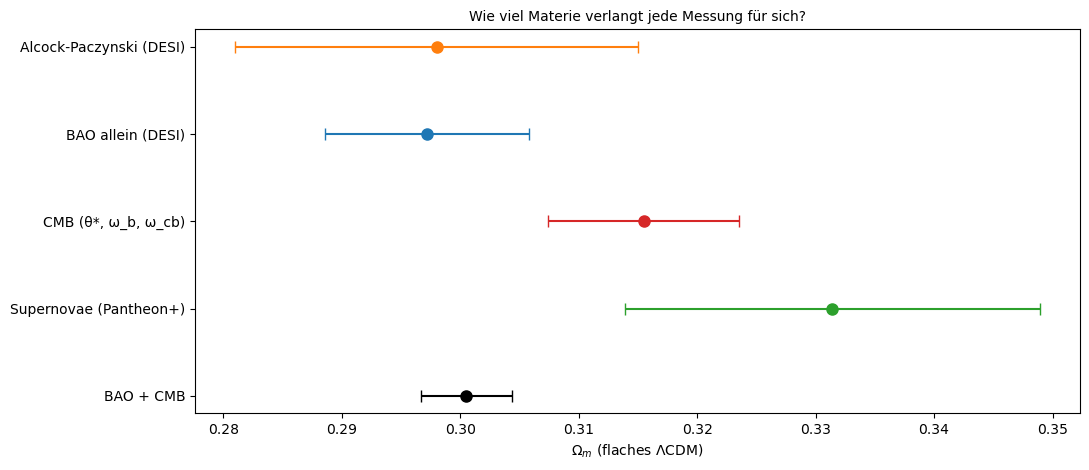

Alcock-Paczynski (DESI)   : Ω_m = 0.2980 ± 0.0170
BAO allein (DESI)         : Ω_m = 0.2972 ± 0.0086
CMB (θ*, ω_b, ω_cb)       : Ω_m = 0.3155 ± 0.0080
Supernovae (Pantheon+)    : Ω_m = 0.3314 ± 0.0175
BAO + CMB                 : Ω_m = 0.3005 ± 0.0038
BAO allein (DESI) gegen CMB (θ*, ω_b, ω_cb): 1.6 σ
BAO allein (DESI) gegen Supernovae (Pantheon+): 1.8 σ
CMB (θ*, ω_b, ω_cb) gegen Supernovae (Pantheon+): 0.8 σ
Supernovae: χ² = 1402.9 bei 1590 Lichtkurven; DESI Tabelle V: DESI 0.2975, CMB 0.3169; Pantheon+ (Brout et al. 2022): 0.334 ± 0.018


In [11]:
c_sn = lambda Om: cosmo(0.7, 0.0224, Om * 0.49 - OMEGA_NU)
oms = np.linspace(0.25, 0.42, 171)
chi_sn = np.array([chi2_sn(c_sn(o)) for o in oms])
r_sn = optimize.minimize_scalar(lambda o: chi2_sn(c_sn(o)), bounds=(0.2, 0.5), method="bounded")
inside = oms[chi_sn - r_sn.fun <= 1]
OM_SN = (r_sn.x, (inside.max() - inside.min()) / 2)
OMEGAS = {"Alcock-Paczynski (DESI)": (OM_AP, OM_AP_ERR, "C1"),
          "BAO allein (DESI)": (BAO2[0][0], np.sqrt(BAO2[1][0, 0]), "C0"),
          "CMB (θ*, ω_b, ω_cb)": (dv_cmb[1], e_cmb[1], "C3"),
          "Supernovae (Pantheon+)": (OM_SN[0], OM_SN[1], "C2"),
          "BAO + CMB": (dv_bc[1], e_bc[1], "k")}
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, (lab, (v, e, col)) in enumerate(OMEGAS.items()):
    ax.errorbar(v, -i, xerr=e, fmt="o", color=col, ms=8, capsize=4)
ax.set_yticks(-np.arange(len(OMEGAS)))
ax.set_yticklabels(list(OMEGAS), fontsize=10)
ax.set_xlabel(r"$\Omega_m$ (flaches ΛCDM)")
ax.set_title("Wie viel Materie verlangt jede Messung für sich?", fontsize=10)
plt.tight_layout()
plt.show()

for lab, (v, e, _) in OMEGAS.items():
    print(f"{lab:26s}: Ω_m = {v:.4f} ± {e:.4f}")
names = ["BAO allein (DESI)", "CMB (θ*, ω_b, ω_cb)", "Supernovae (Pantheon+)"]
for i in range(3):
    for j in range(i + 1, 3):
        (v1, e1, _), (v2, e2, _) = OMEGAS[names[i]], OMEGAS[names[j]]
        print(f"{names[i]} gegen {names[j]}: {abs(v1 - v2) / np.hypot(e1, e2):.1f} σ")
print(f"Supernovae: χ² = {r_sn.fun:.1f} bei {len(Z_SN)} Lichtkurven; DESI Tabelle V: DESI 0.2975, CMB 0.3169; Pantheon+ (Brout et al. 2022): 0.334 ± 0.018")

* $\Omega_m$ aus jeder Messung allein in flachem ΛCDM: Alcock-Paczynski 0.298 ± 0.017, BAO 0.2972 ± 0.0086, CMB 0.3155 ± 0.0080, Supernovae 0.331 ± 0.018. Unten die gemeinsame Anpassung von BAO und CMB, 0.3005 ± 0.0038.
* Die drei unabhängigen Messungen liegen nicht ganz zusammen: BAO gegen CMB 1.6σ, BAO gegen Supernovae 1.8σ, CMB gegen Supernovae 0.8σ. Keine Spannung ist für sich groß, aber die BAO liegen allein am unteren Rand.
* Zur Vorhersage: Die Supernovae geben das größte $\Omega_m$ (Brout et al. 2022: 0.334 ± 0.018). Ein Modell, in dem die Dunkle Energie mit der Zeit abnimmt, kann diese Werte versöhnen: Es macht die Expansion bei kleinem z anders als ΛCDM und verschiebt die drei Größen verschieden stark.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-10"></a>

##### *10. Dunkle Energie mit w₀ und w_a*

Passt ein Modell mit veränderlicher Dunkler Energie besser als ΛCDM, und um wie viel? Vorher vorhersagen: Welche Kombination zieht w₀w_aCDM am stärksten vor, BAO allein, BAO mit CMB oder BAO mit CMB und Supernovae?

Für vier Kombinationen sucht der Code das beste ΛCDM-Modell und das beste w₀w_aCDM-Modell (Theorie, Abschnitt 5), jeweils mit h, $\omega_b$, $\omega_{cb}$ und den flachen Priors von DESI ($-3 \le w_0 \le 1$, $-3 \le w_a \le 2$, $w_0 + w_a < 0$). Aus $\Delta\chi^2$ folgt die Bevorzugung in σ.

Das Bild zeigt für DESI + CMB, wo der Unterschied herkommt. Die Messwerte und das beste w₀w_a-Modell sind durch das beste ΛCDM-Modell geteilt: Wo die Punkte von 1 abweichen, passt ΛCDM schlechter.

**Hintergrund & Fachbegriffe:**
- **Bestes Modell (Maximum der Likelihood):** der Punkt mit dem kleinsten χ²; DESI gibt $\Delta\chi^2_\text{MAP}$ am Maximum der Posterior an, was bei flachen Priors dasselbe ist.
- **Ohne CMB:** Bei BAO allein und BAO mit Supernovae sind h, $\omega_b$ und $\omega_{cb}$ nicht einzeln bestimmt; das stört die Suche nach dem kleinsten χ² nicht, nur die Fehler.

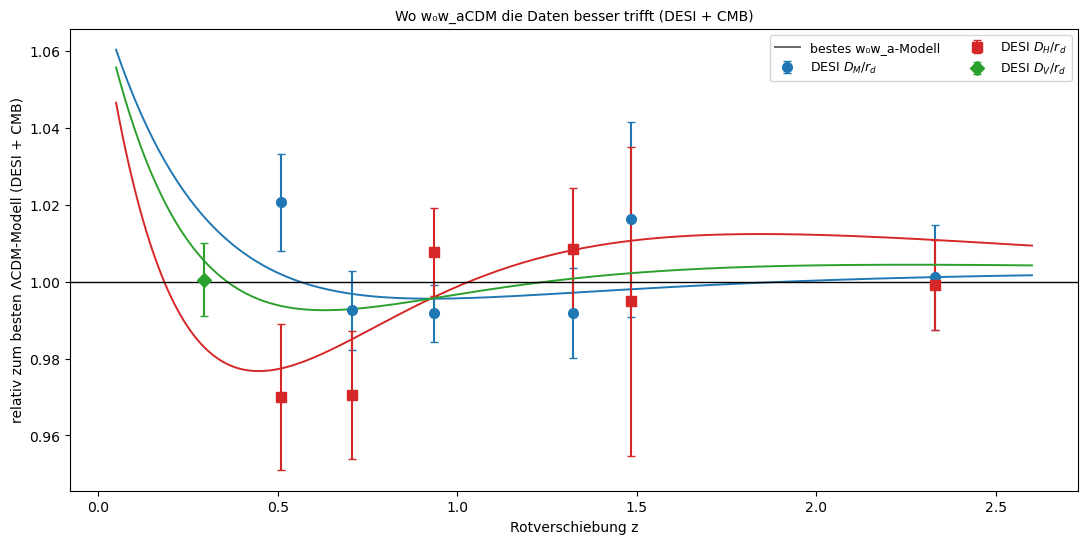

Kombination           χ²(ΛCDM)  χ²(w₀w_a)    Δχ²     σ     w₀      w_a     DESI Tab. VI
DESI                     10.28       5.62   -4.66   1.7  -0.180  -2.708     -4.7 (1.7 σ)
DESI+CMB                 15.05       7.12   -7.93   2.3  -0.448  -1.634     -8.0 (2.4 σ)
DESI+Pantheon+         1416.15    1411.27   -4.88   1.7  -0.890  -0.211     -4.9 (1.7 σ)
DESI+CMB+Pantheon+     1420.84    1413.33   -7.52   2.3  -0.854  -0.519     -10.7 (2.8 σ)
DESI Tab. VI mit voller CMB: DESI+CMB −12.5 (3.1 σ), DESI+CMB+Pantheon+ −10.7 (2.8 σ); DESI+(θ*, ω_b, ω_cb)CMB −8.0 (2.4 σ). Der Wert für DESI+CMB+Pantheon+ stammt aus der vollen CMB.


In [12]:
COMBOS = {"DESI": ("BAO",), "DESI+CMB": ("BAO", "CMB"), "DESI+Pantheon+": ("BAO", "SN"), "DESI+CMB+Pantheon+": ("BAO", "CMB", "SN")}
DESI_TAB6 = {"DESI": (-4.7, 1.7), "DESI+CMB": (-8.0, 2.4), "DESI+Pantheon+": (-4.9, 1.7), "DESI+CMB+Pantheon+": (-10.7, 2.8)}
W_FITS = {}
for key, data in COMBOS.items():
    rl = fit(data)
    rw = fit(data, "w0wa", start=list(rl.x) + [-0.8, -0.6])
    W_FITS[key] = (rl, rw)

c_l = cosmo(*unpack(W_FITS["DESI+CMB"][0].x, "lcdm"))
c_w = cosmo(*unpack(W_FITS["DESI+CMB"][1].x, "w0wa"))
base = bao_model(c_l)
zz = np.linspace(0.05, 2.6, 300)
fig, ax = plt.subplots(figsize=(13, 6))
for kk, (col, mk, lab, j) in {"DM_over_rs": ("C0", "o", r"$D_M/r_d$", 0), "DH_over_rs": ("C3", "s", r"$D_H/r_d$", 1),
                              "DV_over_rs": ("C2", "D", r"$D_V/r_d$", 2)}.items():
    m = KIND == kk
    ax.errorbar(Z_BAO[m], Y_BAO[m] / base[m], yerr=ERR_BAO[m] / base[m], fmt=mk, color=col, ms=7, capsize=3, label="DESI " + lab)
    ax.plot(zz, (distances(c_w, zz)[j] / c_w["rd"]) / (distances(c_l, zz)[j] / c_l["rd"]), color=col, lw=1.4)
ax.axhline(1, color="k", lw=1)
ax.plot([], [], color="0.4", lw=1.4, label="bestes w₀w_a-Modell")
ax.set_xlabel("Rotverschiebung z")
ax.set_ylabel("relativ zum besten ΛCDM-Modell (DESI + CMB)")
ax.set_title("Wo w₀w_aCDM die Daten besser trifft (DESI + CMB)", fontsize=10)
ax.legend(fontsize=9, ncol=2)
plt.show()

print("Kombination           χ²(ΛCDM)  χ²(w₀w_a)    Δχ²     σ     w₀      w_a     DESI Tab. VI")
for key, (rl, rw) in W_FITS.items():
    d = rw.fun - rl.fun
    print(f"{key:20s} {rl.fun:9.2f} {rw.fun:10.2f} {d:7.2f} {sigma(-d):5.1f} {rw.x[3]:7.3f} {rw.x[4]:7.3f}     "
          f"{DESI_TAB6[key][0]} ({DESI_TAB6[key][1]} σ)")
print("DESI Tab. VI mit voller CMB: DESI+CMB −12.5 (3.1 σ), DESI+CMB+Pantheon+ −10.7 (2.8 σ); "
      "DESI+(θ*, ω_b, ω_cb)CMB −8.0 (2.4 σ). Der Wert für DESI+CMB+Pantheon+ stammt aus der vollen CMB.")

* Messwerte (Punkte) und das beste w₀w_a-Modell (Linien) für DESI + CMB, beide geteilt durch das beste ΛCDM-Modell. Das w₀w_a-Modell biegt bei z ≈ 0.5 nach unten: Es trifft die niedrigen $D_H$ bei z = 0.51 und 0.71 und das niedrige $D_M$ bei z = 0.93. Bei z → 0 laufen die Linien weit über 1, weil das w₀w_a-Modell ein viel kleineres H₀ hat (63.7 statt 68.4); dort gibt es aber keine BAO-Messung.
* Die Tabelle: Δχ² = −4.66 (1.7σ) für DESI allein, −7.93 (2.3σ) mit CMB, −4.88 (1.7σ) mit Pantheon+ und −7.52 (2.3σ) mit beiden. Die ersten drei treffen die Werte von DESI (−4.7, −8.0, −4.9) auf 0.1. Für DESI + CMB + Pantheon+ hat DESI nur Zahlen mit der vollen CMB-Likelihood (−10.7, 2.8σ); mit der komprimierten fällt die Bevorzugung um etwa 3 in χ².
* Zur Vorhersage: Die Kombinationen mit CMB ziehen w₀w_aCDM am stärksten vor, weil die CMB in ΛCDM ein anderes $\Omega_m$ will als die BAO (Schritt 8). Die besten Modelle liegen alle bei $w_0 > -1$ und $w_a < 0$, von w₀ = −0.18, w_a = −2.71 (DESI allein, am Rand des Priors) bis −0.85 und −0.52 (alle zusammen).

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-11"></a>

##### *11. Welche Werte von w₀ und w_a erlaubt sind (MCMC)*

Wie weit ist ΛCDM ($w_0 = -1$, $w_a = 0$) vom erlaubten Bereich entfernt, und wie hängt der Bereich von den Daten ab? Vorher vorhersagen: Wie wird die Kontur von DESI + CMB aussehen, rund oder lang gestreckt?

Der Code tastet die Posterior-Verteilung von $(h, \omega_b, \omega_{cb}, w_0, w_a)$ mit einem eigenen Metropolis-Algorithmus ab (Theorie, Abschnitt 7). Er rechnet 20 000 Schritte je Kombination, wirft das erste Viertel weg und passt nach einem Viertel die Vorschlagsverteilung an die Streuung der Kette an. Gestartet wird beim besten Modell aus Schritt 10. Die Konturen enthalten 68 und 95 % der Stichproben, gezählt in einem geglätteten zweidimensionalen Histogramm.

**Hintergrund & Fachbegriffe:**
- **Einlaufphase (Burn-in):** Die ersten Schritte einer Kette hängen noch vom Startpunkt ab und werden verworfen.
- **Akzeptanzrate:** der Anteil angenommener Vorschläge; um 20 bis 40 % läuft eine Kette in wenigen Dimensionen effizient.
- **Marginalisieren:** Eine Kontur in $(w_0, w_a)$ zählt die Stichproben unabhängig davon, welche Werte die übrigen drei Parameter haben.

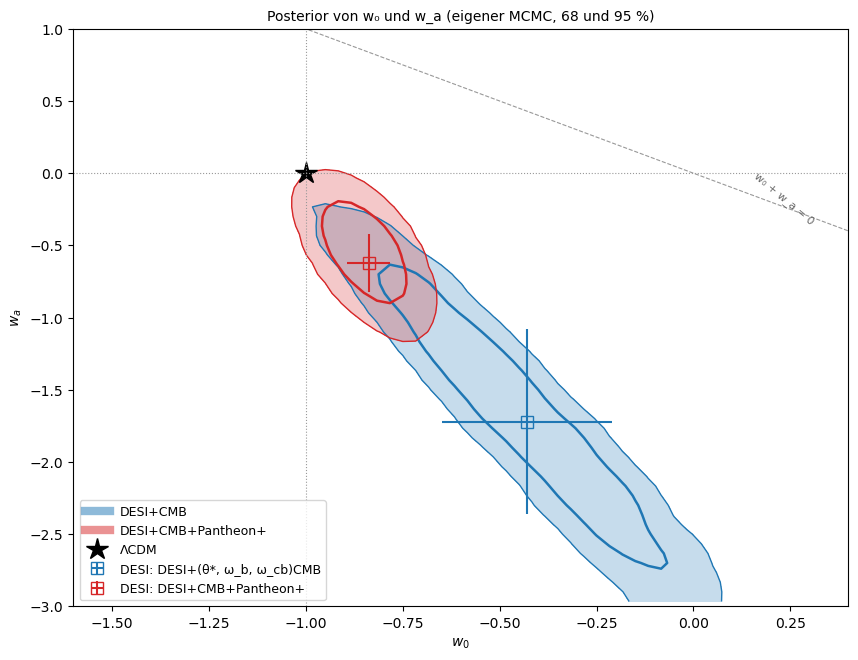

DESI+CMB: Akzeptanz 24 %, w₀ = -0.446 ± 0.223, w_a = -1.67 ± 0.64, H₀ = 63.87 ± 2.03, Ω_m = 0.3504 ± 0.0229; Anteil mit w₀ > −1 und w_a < 0: 99 %
DESI+CMB+Pantheon+: Akzeptanz 27 %, w₀ = -0.847 ± 0.054, w_a = -0.55 ± 0.22, H₀ = 67.47 ± 0.57, Ω_m = 0.3114 ± 0.0055; Anteil mit w₀ > −1 und w_a < 0: 100 %
DESI Tabelle V: DESI+(θ*, ω_b, ω_cb)CMB w₀ = −0.43 ± 0.22, w_a = −1.72 ± 0.64, Ω_m = 0.353 ± 0.022, H₀ = 63.7 +1.7/−2.2; DESI+CMB+Pantheon+ w₀ = −0.838 ± 0.055, w_a = −0.62 +0.22/−0.19, Ω_m = 0.3114 ± 0.0057, H₀ = 67.51 ± 0.59
Rechenzeit der Ketten: 27 s


In [13]:
def metropolis(data, start, n=20000, seed=11):
    rng = np.random.default_rng(seed)
    p = np.array(start, float)
    f = total(p, data, "w0wa")
    try:
        cov0 = covariance(p, data, "w0wa")
        L = np.linalg.cholesky(cov0 * 2.38**2 / len(p))
    except np.linalg.LinAlgError:
        L = np.diag([5e-3, 1e-4, 5e-4, 0.05, 0.2]) * 2.38 / np.sqrt(len(p))
    chain, acc = np.empty((n, len(p))), 0
    for i in range(n):
        q = p + L @ rng.normal(size=len(p))
        g = total(q, data, "w0wa")
        if g < f or rng.random() < np.exp((f - g) / 2):
            p, f, acc = q, g, acc + 1
        chain[i] = p
        if i == n // 4:                                  # Vorschläge einmal an die bisherige Kette anpassen
            L = np.linalg.cholesky(np.cov(chain[n // 8:i].T) * 2.38**2 / len(p) + 1e-12 * np.eye(len(p)))
    return chain[n // 4:], acc / n


def levels(H, fracs=(0.68, 0.95)):
    v = np.sort(H.ravel())[::-1]
    c = np.cumsum(v) / v.sum()
    return sorted(v[np.searchsorted(c, f)] for f in fracs)


t0 = time.time()
CHAINS = {key: metropolis(COMBOS[key], W_FITS[key][1].x) for key in ["DESI+CMB", "DESI+CMB+Pantheon+"]}
fig, ax = plt.subplots(figsize=(10, 7.5))
for (key, (ch, acc)), col in zip(CHAINS.items(), ["C0", "C3"]):
    H, xe, ye = np.histogram2d(ch[:, 3], ch[:, 4], bins=60, range=[[-1.6, 0.4], [-3.0, 1.0]])
    H = ndimage.gaussian_filter(H, 1.5)
    xc, yc = (xe[1:] + xe[:-1]) / 2, (ye[1:] + ye[:-1]) / 2
    ax.contourf(xc, yc, H.T, levels=levels(H) + [H.max()], colors=[col, col], alpha=0.25)
    ax.contour(xc, yc, H.T, levels=levels(H), colors=[col], linewidths=[1, 1.8])
    ax.plot([], [], color=col, lw=6, alpha=0.5, label=key)
ax.plot(-1, 0, "k*", ms=16, label="ΛCDM")
ax.errorbar(-0.43, -1.72, xerr=0.22, yerr=0.64, fmt="s", color="C0", mfc="none", ms=8, label="DESI: DESI+(θ*, ω_b, ω_cb)CMB")
ax.errorbar(-0.838, -0.62, xerr=0.055, yerr=0.2, fmt="s", color="C3", mfc="none", ms=8, label="DESI: DESI+CMB+Pantheon+")
ax.axhline(0, color="0.6", lw=0.8, ls=":")
ax.axvline(-1, color="0.6", lw=0.8, ls=":")
ax.plot([-1.6, 0.4], [1.6, -0.4], color="0.6", lw=0.8, ls="--")
ax.text(0.15, -0.35, "w₀ + w_a = 0", fontsize=8, color="0.4", rotation=-40)
ax.set_xlim(-1.6, 0.4)
ax.set_ylim(-3.0, 1.0)
ax.set_xlabel(r"$w_0$")
ax.set_ylabel(r"$w_a$")
ax.set_title("Posterior von w₀ und w_a (eigener MCMC, 68 und 95 %)", fontsize=10)
ax.legend(fontsize=9, loc="lower left")
plt.show()

for key, (ch, acc) in CHAINS.items():
    dv = np.array([derived(p, "w0wa") for p in ch[::20]])
    lam = np.mean((ch[:, 3] > -1) & (ch[:, 4] < 0))
    print(f"{key}: Akzeptanz {100 * acc:.0f} %, w₀ = {ch[:, 3].mean():.3f} ± {ch[:, 3].std():.3f}, w_a = {ch[:, 4].mean():.2f} ± {ch[:, 4].std():.2f}, "
          f"H₀ = {dv[:, 0].mean():.2f} ± {dv[:, 0].std():.2f}, Ω_m = {dv[:, 1].mean():.4f} ± {dv[:, 1].std():.4f}; "
          f"Anteil mit w₀ > −1 und w_a < 0: {100 * lam:.0f} %")
print("DESI Tabelle V: DESI+(θ*, ω_b, ω_cb)CMB w₀ = −0.43 ± 0.22, w_a = −1.72 ± 0.64, Ω_m = 0.353 ± 0.022, H₀ = 63.7 +1.7/−2.2; "
      "DESI+CMB+Pantheon+ w₀ = −0.838 ± 0.055, w_a = −0.62 +0.22/−0.19, Ω_m = 0.3114 ± 0.0057, H₀ = 67.51 ± 0.59")
print(f"Rechenzeit der Ketten: {time.time() - t0:.0f} s")

* Die Bereiche von $w_0$ und $w_a$ mit 68 und 95 % der Posterior: blau DESI + CMB, rot zusätzlich Pantheon+, der Stern ist ΛCDM, die offenen Quadrate sind die Werte von DESI. Die blaue Kontur ist ein langes Band entlang einer Entartung und stößt unten an den Prior $w_a \ge -3$. Die Supernovae schneiden aus diesem Band ein kleines Stück nahe ΛCDM heraus.
* Mittelwerte: DESI + CMB $w_0 = -0.446 \pm 0.223$, $w_a = -1.67 \pm 0.64$, H₀ = 63.9 ± 2.0, $\Omega_m$ = 0.350 ± 0.023 (DESI mit komprimierter CMB: −0.43 ± 0.22, −1.72 ± 0.64, 63.7, 0.353). Mit Pantheon+: $w_0 = -0.847 \pm 0.054$, $w_a = -0.55 \pm 0.22$, H₀ = 67.47 ± 0.57, $\Omega_m$ = 0.3114 ± 0.0055 (DESI mit voller CMB: −0.838 ± 0.055, −0.62, 67.51 ± 0.59, 0.3114 ± 0.0057). Die Ketten nehmen 24 und 27 % der Vorschläge an.
* Zur Vorhersage: lang gestreckt. BAO und CMB legen vor allem die Expansion bei z ≈ 0.5 bis 1 fest; ein größeres $w_0$ lässt sich dort durch ein kleineres $w_a$ ausgleichen. ΛCDM liegt bei DESI + CMB außerhalb der 95-%-Kontur; 99 % der Stichproben haben $w_0 > -1$ und $w_a < 0$, mit Pantheon+ alle.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-12"></a>

##### *12. Was w₀ und w_a für die Dunkle Energie bedeuten*

Wie hätte sich die Dunkle Energie mit der Zeit verändert, wenn das bevorzugte Modell stimmt? Vorher vorhersagen: Ist ihre Dichte heute größer oder kleiner als bei z = 0.5?

Aus 2000 Stichproben der Kette für DESI + CMB + Pantheon+ rechnet der Code für jedes z die Zustandsgleichung $w(z)$ und die Dichte $\rho_\text{DE}(z)/\rho_\text{DE,0}$ (Theorie, Abschnitt 5) und zeichnet den Median mit dem Band, das 68 % der Stichproben enthält. Dazu gibt er die Rotverschiebung aus, bei der $w$ die Grenze −1 kreuzt, und wo die Dichte ihr Maximum hat.

**Hintergrund & Fachbegriffe:**
- **Phantom-Kreuzung:** Ein einzelnes skalares Feld mit gewöhnlicher kinetischer Energie kann $w = -1$ nicht überschreiten. Ein Wechsel von $w < -1$ zu $w > -1$ verlangt deshalb mehrere Felder, eine Kopplung an die Dunkle Materie oder bedeutet, dass die Parametrisierung nur eine Näherung ist.
- **Band der Posterior:** An jedem z sind das 16. und 84. Perzentil der Werte aus allen Stichproben eingezeichnet.

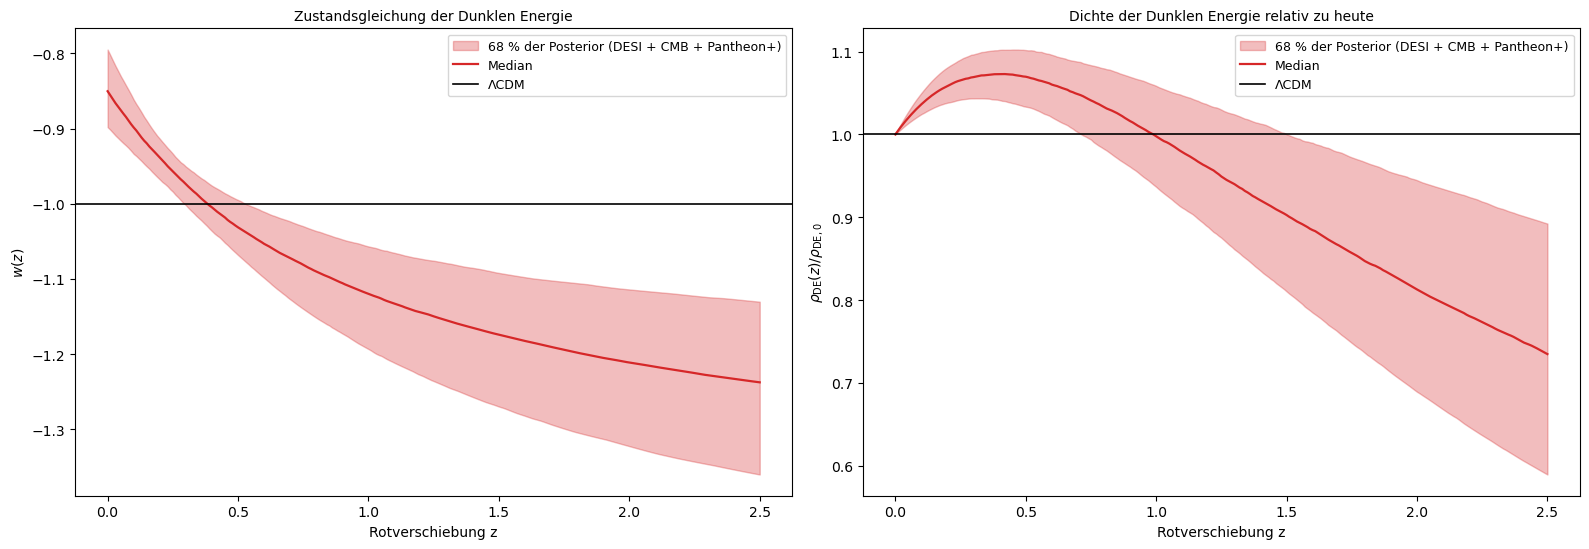

bestes Modell: w₀ = -0.854, w_a = -0.519; w = −1 bei z = 0.39; Maximum der Dichte bei z = 0.39 (1.071 × heute); früh (z = 2.5) w = -1.22
Kreuzung in den Stichproben: Median z = 0.38, 68 % zwischen 0.29 und 0.53
Dichte bei z = 0.5: 1.070 × heute (1.034 bis 1.102)


In [14]:
ch = CHAINS["DESI+CMB+Pantheon+"][0]
draw = ch[np.random.default_rng(3).choice(len(ch), 2000, replace=False)]
zz = np.linspace(0, 2.5, 251)
a = 1 / (1 + zz)
w = draw[:, 3:4] + draw[:, 4:5] * (1 - a)
rho = a ** (-3 * (1 + draw[:, 3:4] + draw[:, 4:5])) * np.exp(-3 * draw[:, 4:5] * (1 - a))
best = W_FITS["DESI+CMB+Pantheon+"][1].x
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
for axx, y, lab in [(ax, w, r"$w(z)$"), (ax2, rho, r"$\rho_\mathrm{DE}(z)/\rho_\mathrm{DE,0}$")]:
    lo, med, hi = np.percentile(y, [16, 50, 84], axis=0)
    axx.fill_between(zz, lo, hi, color="C3", alpha=0.3, label="68 % der Posterior (DESI + CMB + Pantheon+)")
    axx.plot(zz, med, color="C3", lw=1.6, label="Median")
    axx.axhline(-1 if axx is ax else 1, color="k", lw=1.2, label="ΛCDM")
    axx.set_xlabel("Rotverschiebung z")
    axx.set_ylabel(lab)
    axx.legend(fontsize=9)
ax.set_title("Zustandsgleichung der Dunklen Energie", fontsize=10)
ax2.set_title("Dichte der Dunklen Energie relativ zu heute", fontsize=10)
plt.tight_layout()
plt.show()

w0b, wab = best[3], best[4]
z_cross = 1 / (1 + (1 + w0b) / wab) - 1
rho_b = a ** (-3 * (1 + w0b + wab)) * np.exp(-3 * wab * (1 - a))
cross = 1 / (1 + (1 + draw[:, 3]) / draw[:, 4]) - 1
print(f"bestes Modell: w₀ = {w0b:.3f}, w_a = {wab:.3f}; w = −1 bei z = {z_cross:.2f}; Maximum der Dichte bei z = {zz[np.argmax(rho_b)]:.2f} "
      f"({rho_b.max():.3f} × heute); früh (z = 2.5) w = {w0b + wab * (1 - a[-1]):.2f}")
print(f"Kreuzung in den Stichproben: Median z = {np.median(cross[(cross > 0) & (cross < 10)]):.2f}, "
      f"68 % zwischen {np.percentile(cross[(cross > 0) & (cross < 10)], 16):.2f} und {np.percentile(cross[(cross > 0) & (cross < 10)], 84):.2f}")
print(f"Dichte bei z = 0.5: {np.median(rho[:, 50]):.3f} × heute ({np.percentile(rho[:, 50], 16):.3f} bis {np.percentile(rho[:, 50], 84):.3f})")

* Links $w(z)$, rechts die Dichte der Dunklen Energie relativ zu heute, Median und 68-%-Band der Posterior für DESI + CMB + Pantheon+, schwarz ΛCDM. Heute ist $w \approx -0.85$; zu früheren Zeiten fällt $w$ unter −1 und erreicht bei z = 2.5 etwa −1.22.
* Das beste Modell kreuzt $w = -1$ bei z = 0.39; in den Stichproben liegt die Kreuzung mit 68 % zwischen z = 0.29 und 0.53. Genau dort hat die Dichte ihr Maximum, 7 % über dem heutigen Wert, und fällt seither. Bei z = 0.5 ist sie 1.070-mal so groß wie heute (1.034 bis 1.102); bei z > 1 ist sie kleiner als heute.
* Zur Vorhersage: Bei z = 0.5 war die Dunkle Energie dichter als heute. In diesem Modell hat ihre Dichte vor etwa 4 Milliarden Jahren ein Maximum erreicht und nimmt seither ab, statt konstant zu bleiben. Ein einzelnes einfaches Feld kann das nicht (Phantom-Kreuzung); auch das ist ein Grund, das Ergebnis vorsichtig zu lesen.

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung gegen den Katalog**

<a id="exp-13"></a>

##### *13. Gegen DESI DR2 und die Entfernungsleiter*

Wie gut stimmen die eigenen Zahlen mit denen von DESI überein, und was bleibt von der Hubble-Spannung? Vorher vorhersagen: Welcher der eigenen Werte für H₀ liegt am weitesten von SH0ES?

Der Code stellt die eigenen Ergebnisse neben die Tabellen V und VI von DESI DR2: $\Omega_m$ und $h\,r_d$ aus den BAO allein, H₀ aus der inversen Entfernungsleiter, ΛCDM mit CMB, w₀ und w_a. Im Bild stehen alle Werte für H₀ untereinander, mit SH0ES, Planck und dem Wert aus [Die akustischen Peaks](https://github.com/deltorobarba/science/blob/main/astro/cosmology_cmbpeaks.ipynb).

**Hintergrund & Fachbegriffe:**
- **Posterior-Mittel gegen bestes Modell:** DESI gibt Mittelwerte der Posterior an; bei w₀w_aCDM liegen sie wegen der schiefen Verteilung neben dem besten Modell. Verglichen wird deshalb mit den Mitteln der eigenen Ketten.
- **Inverse gegen direkte Entfernungsleiter:** Beide messen H₀ mit einem Lineal; die eine eicht es an der Physik vor der Rekombination, die andere an Cepheiden. Weichen sie ab, stimmt eines der Lineale nicht oder die Expansion zwischen ihnen verläuft anders als in ΛCDM.

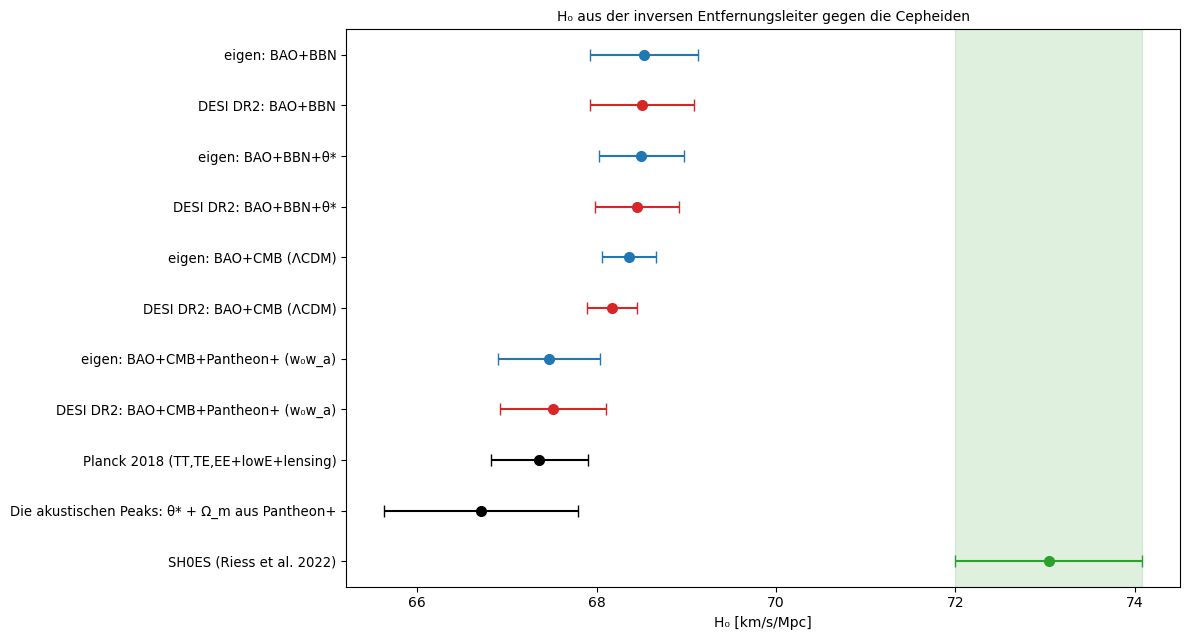

BAO allein:  Ω_m 0.2972 ± 0.0086 (DESI 0.2975 ± 0.0086), h r_d 101.55 ± 0.74 (101.54 ± 0.73)
BAO+BBN                     : H₀ = 68.53 ± 0.60 (DESI 68.51 ± 0.58), gegen SH0ES 3.7 σ
BAO+BBN+θ*                  : H₀ = 68.50 ± 0.48 (DESI 68.45 ± 0.47), gegen SH0ES 4.0 σ
BAO+CMB (ΛCDM)              : H₀ = 68.36 ± 0.30 (DESI 68.17 ± 0.28), gegen SH0ES 4.3 σ
BAO+CMB+Pantheon+ (w₀w_a)   : H₀ = 67.47 ± 0.57 (DESI 67.51 ± 0.59), gegen SH0ES 4.7 σ
DESI+CMB                    : w₀ = -0.446 ± 0.223, w_a = -1.67 ± 0.64
DESI+CMB+Pantheon+          : w₀ = -0.847 ± 0.054, w_a = -0.55 ± 0.22


In [15]:
own = {"BAO+BBN": (FITS["BAO+BBN"][2][0], np.sqrt(FITS["BAO+BBN"][3][0, 0])),
       "BAO+BBN+θ*": (FITS["BAO+BBN+θ*"][2][0], np.sqrt(FITS["BAO+BBN+θ*"][3][0, 0])),
       "BAO+CMB (ΛCDM)": (dv_bc[0], e_bc[0])}
dvw = np.array([derived(p, "w0wa") for p in CHAINS["DESI+CMB+Pantheon+"][0][::20]])
own["BAO+CMB+Pantheon+ (w₀w_a)"] = (dvw[:, 0].mean(), dvw[:, 0].std())
desi = {"BAO+BBN": (68.51, 0.58), "BAO+BBN+θ*": (68.45, 0.47), "BAO+CMB (ΛCDM)": (68.17, 0.28), "BAO+CMB+Pantheon+ (w₀w_a)": (67.51, 0.59)}
rows = []
for key in own:
    rows += [(f"eigen: {key}", *own[key], "C0"), (f"DESI DR2: {key}", *desi[key], "C3")]
rows += [("Planck 2018 (TT,TE,EE+lowE+lensing)", *PLANCK["H0"], "k"), ("Die akustischen Peaks: θ* + Ω_m aus Pantheon+", 66.71, 1.08, "k"),
         ("SH0ES (Riess et al. 2022)", *H0_SH0ES, "C2")]
fig, ax = plt.subplots(figsize=(12, 6.5))
for i, (lab, v, e, col) in enumerate(rows):
    ax.errorbar(v, -i, xerr=e, fmt="o", color=col, ms=7, capsize=4)
ax.set_yticks(-np.arange(len(rows)))
ax.set_yticklabels([r[0] for r in rows], fontsize=9.5)
ax.axvspan(H0_SH0ES[0] - H0_SH0ES[1], H0_SH0ES[0] + H0_SH0ES[1], color="C2", alpha=0.15)
ax.set_xlabel("H₀ [km/s/Mpc]")
ax.set_title("H₀ aus der inversen Entfernungsleiter gegen die Cepheiden", fontsize=10)
plt.tight_layout()
plt.show()

e4 = np.sqrt(np.diag(BAO2[1]))
print(f"BAO allein:  Ω_m {BAO2[0][0]:.4f} ± {e4[0]:.4f} (DESI 0.2975 ± 0.0086), h r_d {BAO2[0][1]:.2f} ± {e4[1]:.2f} (101.54 ± 0.73)")
for key in own:
    v, e = own[key]
    print(f"{key:28s}: H₀ = {v:.2f} ± {e:.2f} (DESI {desi[key][0]} ± {desi[key][1]}), gegen SH0ES {(H0_SH0ES[0] - v) / np.hypot(e, H0_SH0ES[1]):.1f} σ")
for key, (ch, acc) in CHAINS.items():
    print(f"{key:28s}: w₀ = {ch[:, 3].mean():.3f} ± {ch[:, 3].std():.3f}, w_a = {ch[:, 4].mean():.2f} ± {ch[:, 4].std():.2f}")

* Alle Werte von H₀ untereinander, blau eigene, rot DESI DR2, schwarz Planck und die Hintergrundstrahlung aus [Die akustischen Peaks](https://github.com/deltorobarba/science/blob/main/astro/cosmology_cmbpeaks.ipynb), grün SH0ES. Die eigenen Werte treffen die von DESI jeweils innerhalb von 0.2 km/s/Mpc; die größte Abweichung ist BAO + CMB in ΛCDM (68.36 gegen 68.17), weil hier die komprimierte statt der vollen CMB-Likelihood steckt.
* BAO allein: $\Omega_m$ = 0.2972 ± 0.0086 und $h\,r_d$ = 101.55 ± 0.74 Mpc (DESI 0.2975 und 101.54). Die Werte von H₀ liegen zwischen 67.47 ± 0.57 (w₀w_a mit Pantheon+) und 68.53 ± 0.60 (BAO + BBN), 3.7 bis 4.7σ unter SH0ES.
* Zur Vorhersage: Am weitesten von SH0ES liegt das w₀w_a-Modell mit Pantheon+ (4.7σ). Die veränderliche Dunkle Energie löst die Hubble-Spannung also nicht, sie macht sie eher größer: Sie ändert die Expansion bei z < 1, die Leitern unterscheiden sich aber im Maßstab ($r_d$ gegen $M_B$, Schritt 3).

[↑ Zurück zur Landkarte](#landkarte)

#### **Ergebnis**

Beim Lauf vom 2026-11-08 (DESI DR2 BAO mit Kovarianz, Pantheon+ ab z = 0.01, komprimierte CMB-Likelihood von DESI, BBN nach Schöneberg 2024; Näherungen für z* und z_d an Planck geeicht):

- **Die Messungen:** 13 Entfernungen in Einheiten von $r_d$, auf 0.7 bis 4 % genau. Gegen Planck-ΛCDM ist χ² = 30.0, die meisten Werte liegen 1 bis 4 % darunter.
- **Ohne Maßstab:** Der Alcock-Paczynski-Test allein gibt $\Omega_m$ = 0.298 ± 0.017. Alle BAO zusammen geben **$\Omega_m$ = 0.2972 ± 0.0086 und $h\,r_d$ = 101.55 ± 0.74 Mpc** (DESI: 0.2975 ± 0.0086, 101.54 ± 0.73).
- **Zwei Leitern:** Mit $r_d$ von Planck und $M_B$ der Cepheiden liegen BAO und Supernovae um 8.9 % auseinander; das ist die Hubble-Spannung als Unterschied zweier Maßstäbe.
- **Schallhorizont:** $r_d$ = 147.09 Mpc bei $z_d$ = 1059.9, 1.8 % mehr als $r_\star$. Die Empfindlichkeiten −0.257 (ω_cb) und −0.130 (ω_b) stimmen mit Aubourg et al. überein. Die Korrelationsfunktion nach Eisenstein & Hu zeigt den Buckel bei 149 Mpc.
- **Inverse Entfernungsleiter:** **H₀ = 68.53 ± 0.60** aus BAO und BBN, 68.50 ± 0.48 mit θ* (DESI: 68.51 ± 0.58, 68.45 ± 0.47), 3.7 und 4.0σ unter SH0ES.
- **ΛCDM mit CMB:** Die BAO liegen 1.8σ neben der Vorhersage der komprimierten CMB-Likelihood (DESI mit voller CMB: 2.3σ). Zusammen: H₀ = 68.36 ± 0.30, $\Omega_m$ = 0.3005 ± 0.0038. Allein geben BAO 0.297, CMB 0.316 und Supernovae 0.331 für $\Omega_m$.
- **w₀w_aCDM:**
  - Die Bevorzugung gegenüber ΛCDM ist 1.7σ mit DESI allein, 2.3σ mit CMB (Δχ² = −7.9, DESI −8.0), 1.7σ mit Pantheon+ und 2.3σ mit CMB und Pantheon+ (DESI mit voller CMB: 2.8σ).
  - MCMC mit DESI + CMB + Pantheon+: **w₀ = −0.847 ± 0.054, w_a = −0.55 ± 0.22**, H₀ = 67.47 ± 0.57 (DESI: −0.838 ± 0.055, −0.62, 67.51 ± 0.59).
  - In diesem Modell kreuzt w die Grenze −1 bei z ≈ 0.39, und die Dichte der Dunklen Energie war dort 7 % größer als heute.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und das Notebook neu ausführen:

1. **Ohne den Lyman-α-Wald:** Nach dem Laden nur die Werte mit z < 2 behalten (`keep = Z_BAO < 2` auf `Z_BAO`, `Y_BAO`, `KIND` und `COV_BAO` anwenden). *(Vorhersage: Der einzige Punkt bei hohem z verlängert den Hebel. Ohne ihn wird $\Omega_m$ = 0.299 ± 0.013 statt ± 0.009, und $h\,r_d$ = 101.46 ± 0.91. H₀ aus BAO und BBN bleibt bei 68.6, der Abstand zur CMB bei 1.8σ.)*
2. **Nur die Diagonale der Kovarianz:** `IC_BAO = np.diag(1 / np.diag(COV_BAO))`. *(Vorhersage: Ohne die negative Korrelation von $D_M$ und $D_H$ zählt jede Stichprobe zu viel; $\Omega_m$ wird 0.2996 ± 0.0094 und $h\,r_d$ = 101.33 ± 0.78, χ² steigt von 10.28 auf 11.13. Die Unterschiede sind klein, weil die Korrelation nur in Paaren wirkt.)*
3. **Die Näherung für z_d nicht eichen:** `K_ZDRAG = 1.0`. *(Vorhersage: $r_d$ wird 150.74 statt 147.09 Mpc, 2.5 % mehr. H₀ aus BAO und BBN fällt aber um 4.9 % auf 65.17, nicht um 2.5 %: $r_d$ hängt über $\omega_{cb} = \Omega_m h^2$ selbst von h ab, wie $h^{-0.5}$, und $h\,r_d$ wächst nur wie $h^{0.5}$. Mit θ* dazu passt das Modell nicht mehr: H₀ = 66.64 bei $\Omega_m$ = 0.329.)*
4. **BBN mit freiem N_eff:** `BBN = (0.02196, 0.00063)` statt (0.02218, 0.00055) (DESI Gl. 15). *(Vorhersage: Weniger Baryonen machen $r_d$ länger, H₀ fällt auf 68.35 ± 0.65; der Abstand zu SH0ES bleibt fast gleich.)*
5. **Ohne die nahen Supernovae:** `use = SN["zHD"].values > 0.023`, wie bei vielen Analysen, die die Eigenbewegungen fürchten. *(Vorhersage: Es bleiben 1371 statt 1590 Lichtkurven, $\Omega_m$ der Supernovae wird 0.328 ± 0.018. Die Bevorzugung von w₀w_aCDM mit CMB und Supernovae fällt von Δχ² = −7.5 (2.3σ) auf −5.9 (1.9σ): Ein Teil des Signals kommt aus dem Übergang zwischen nahen und fernen Supernovae.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum gibt es in der Verteilung der Galaxien einen bevorzugten Abstand von 147 Mpc?</summary>

Um jede Überdichte im frühen Universum lief eine Schallwelle im Plasma aus Photonen und Baryonen nach außen. Als die Baryonen bei $z_d \approx 1060$ vom Licht frei kamen, blieb eine Schale aus Baryonen im Abstand $r_d$ stehen. Galaxien entstanden bevorzugt in der Mitte und auf der Schale, deshalb findet man Paare im Abstand $r_d$ etwas häufiger.
</details>

<details><summary>2. Was messen D_M/r_d und D_H/r_d, und warum misst DESI keine Entfernung in Mpc?</summary>

$D_M/r_d$ kommt aus dem Winkel, unter dem das Lineal quer zur Sichtlinie erscheint, $D_H/r_d = c/(H r_d)$ aus seiner Ausdehnung in der Rotverschiebung längs der Sichtlinie. Gemessen wird nur, wie oft das Lineal in eine Entfernung passt; seine Länge in Mpc kommt nicht aus den Galaxien.
</details>

<details><summary>3. Welche zwei Zahlen legen BAO allein in flachem ΛCDM fest?</summary>

$\Omega_m$ (aus der Form, wie sich die Verhältnisse mit z ändern) und $h\,r_d$ (aus dem gemeinsamen Faktor $c/(H_0 r_d)$). $H_0$ und $r_d$ einzeln bleiben offen.
</details>

<details><summary>4. Warum braucht der Alcock-Paczynski-Test kein Lineal?</summary>

$D_M/D_H$ ist das Verhältnis zweier Entfernungen bei derselben Rotverschiebung. $r_d$ und $H_0$ kürzen sich heraus, übrig bleibt $E(z)\int dz/E$, das nur von der Form der Expansion abhängt.
</details>

<details><summary>5. Warum ist r_d größer als der Schallhorizont r* der Hintergrundstrahlung?</summary>

Die Photonen entkoppeln bei $z_\star \approx 1090$. Auf jedes Baryon kommen aber über eine Milliarde Photonen, deshalb spüren die Baryonen den Strahlungsdruck noch, bis $z_d \approx 1060$. Der Schall läuft also länger, und $r_d$ ist 1.8 % größer.
</details>

<details><summary>6. Wie funktioniert die inverse Entfernungsleiter?</summary>

Die Länge $r_d$ wird aus der Physik vor der Rekombination berechnet: aus $\omega_b$ (Nukleosynthese) und $\omega_{cb}$. Die BAO messen $h\,r_d$; mit bekanntem $r_d$ folgt $h$. Dabei hängt $r_d$ über $\omega_{cb} = \Omega_m h^2$ selbst von $h$ ab; beides wird zusammen gelöst.
</details>

<details><summary>7. Warum wird ein Fehler von 2.5 % in r_d zu fast 5 % in H₀?</summary>

Bei festem $\Omega_m$ ist $r_d \propto \omega_{cb}^{-0.25} \propto h^{-0.5}$. Die BAO legen $h\,r_d \propto h^{0.5}$ fest; ein um 2.5 % größeres $r_d$ verlangt deshalb ein um etwa 5 % kleineres $h$.
</details>

<details><summary>8. Was zeigt das Diagramm mit BAO und Supernovae über die Hubble-Spannung?</summary>

Die Form der Expansionsgeschichte stimmt bei beiden Leitern fast überein, aber ihr Maßstab nicht: Mit $r_d$ von Planck und $M_B$ der Cepheiden liegen sie 8.9 % auseinander. Entweder ist einer der beiden Maßstäbe falsch, oder zwischen ihnen passiert etwas, das ΛCDM nicht kennt.
</details>

<details><summary>9. Was bedeuten w₀ > −1 und w_a < 0?</summary>

Heute ist $w = w_0 > -1$, die Dichte der Dunklen Energie nimmt also ab. Früher war $w = w_0 + w_a < -1$, die Dichte nahm zu. Dazwischen hatte sie ein Maximum; bei den Daten hier bei z ≈ 0.4.
</details>

<details><summary>10. Warum ist Δχ² = −8 bei zwei zusätzlichen Parametern „nur“ 2.4σ?</summary>

Mit zwei freien Parametern mehr sinkt χ² im Mittel um 2, auch wenn ΛCDM stimmt. Die Wahrscheinlichkeit, dass es zufällig um 8 oder mehr sinkt, ist $e^{-4} = 1.8$ %; das entspricht 2.4σ einer Normalverteilung.
</details>

<details><summary>11. Warum ist die Kontur von DESI + CMB in w₀ und w_a so lang gestreckt?</summary>

BAO und CMB legen vor allem die Expansion bei z ≈ 0.5 bis 1 fest. Dort lässt sich ein größeres $w_0$ durch ein negativeres $w_a$ ausgleichen; entlang dieser Linie ändern sich die Vorhersagen kaum. Erst die Supernovae, die bis z ≈ 0 reichen, schneiden ein Stück heraus.
</details>

<details><summary>12. Löst eine veränderliche Dunkle Energie die Hubble-Spannung?</summary>

Nein. Mit w₀w_a ist H₀ aus BAO, CMB und Supernovae 67.5, eher weiter von SH0ES (4.7σ) als in ΛCDM. Die veränderliche Dunkle Energie ändert die Form der Expansion bei z < 1; die Hubble-Spannung ist ein Unterschied der Maßstäbe $r_d$ und $M_B$.
</details>

<details><summary>13. Warum ist das Ergebnis zur Dunklen Energie mit Vorsicht zu lesen?</summary>

Die Bevorzugung hängt davon ab, welche Supernovae man nimmt (2.8 bis 4.2σ bei DESI) und welche davon; ohne die nahen Supernovae fällt sie hier von 2.3 auf 1.9σ. Außerdem verlangt das bevorzugte Modell eine Phantom-Kreuzung, die ein einfaches Feld nicht kann, und $w_0 + w_a(1-a)$ ist nur eine Näherung für eine unbekannte Funktion.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Der volle Fit:** Cobaya mit der vollen Likelihood von Planck (oder Planck und ACT) und einem Boltzmann-Code statt der komprimierten Likelihood; DESI findet damit 3.1σ für DESI + CMB statt 2.4σ.
- **Andere Supernovae:** Union3 und DES-SN5YR statt Pantheon+; bei DESI wächst die Bevorzugung damit auf 3.8 und 4.2σ. Diskutiert wird, ob die Kalibrierung zwischen nahen und fernen Supernovae das Signal erzeugt.
- **Andere Formen für w(z):** Statt $w_0 + w_a(1-a)$ eine Rekonstruktion in Bins der Rotverschiebung oder physikalische Modelle (Quintessenz, an Dunkle Materie gekoppelte Dunkle Energie), um zu sehen, welche Merkmale die Daten wirklich verlangen.
- **Neutrinomassen:** Die BAO mit der CMB begrenzen die Summe der Neutrinomassen auf unter 0.064 eV (DESI, ΛCDM), knapp an der Untergrenze aus Oszillationsexperimenten (0.059 eV); ein Fit mit freier Masse zeigt diese Spannung.
- **Die Korrelationsfunktion selbst:** Statt der fertigen Entfernungen die Galaxien von DESI selbst auswerten: Korrelationsfunktion messen, den Buckel mit einer Schablone anpassen und $D_M/r_d$ und $D_H/r_d$ selbst bestimmen.

#### **Referenzen**

- Dodelson, S. & Schmidt, F. (2020): *Modern Cosmology*, 2. Aufl., Academic Press, Kap. 2 (Entfernungen), 8 (Leistungsspektrum, Transferfunktion) und 11 (Tracer, BAO).
- Weinberg, D. H. et al. (2013): *Observational probes of cosmic acceleration*, Phys. Rep. 530, 87, Abschnitt 4 (BAO, Alcock-Paczynski).
- DESI Collaboration, Abdul-Karim, M. et al. (2025): *DESI DR2 Results II: Measurements of Baryon Acoustic Oscillations and Cosmological Constraints*, Phys. Rev. D 112, 083515, arXiv:2503.14738 (Tabellen IV bis VI, Anhang A).
- Eisenstein, D. J. et al. (2005): *Detection of the baryon acoustic peak in the large-scale correlation function of SDSS luminous red galaxies*, ApJ 633, 560.
- Cole, S. et al. (2005): *The 2dF Galaxy Redshift Survey: power-spectrum analysis of the final data set and cosmological implications*, MNRAS 362, 505.
- Eisenstein, D. J. & Hu, W. (1998): *Baryonic features in the matter transfer function*, ApJ 496, 605 (Gl. 2 bis 24).
- Hu, W. & Sugiyama, N. (1996): *Small-scale cosmological perturbations: an analytic approach*, ApJ 471, 542 (Gl. E1).
- Aubourg, É. et al. (2015): *Cosmological implications of baryon acoustic oscillation measurements*, Phys. Rev. D 92, 123516 (Gl. 16, r_d).
- Alcock, C. & Paczynski, B. (1979): *An evolution free test for non-zero cosmological constant*, Nature 281, 358.
- Chevallier, M. & Polarski, D. (2001): *Accelerating universes with scaling dark matter*, Int. J. Mod. Phys. D 10, 213; Linder, E. V. (2003): *Exploring the expansion history of the universe*, Phys. Rev. Lett. 90, 091301.
- Schöneberg, N. (2024): *The 2024 BBN baryon abundance update*, JCAP 06, 006, arXiv:2401.15054.
- Lemos, P. & Lewis, A. (2023): *CMB constraints on the early Universe independent of late-time cosmology*, Phys. Rev. D 107, 103505.
- Gelman, A., Roberts, G. O. & Gilks, W. R. (1996): *Efficient Metropolis jumping rules*, Bayesian Statistics 5, 599.
- Scolnic, D. et al. (2022): *The Pantheon+ analysis: the full data set and light-curve release*, ApJ 938, 113; Brout, D. et al. (2022): *The Pantheon+ analysis: cosmological constraints*, ApJ 938, 110.
- Riess, A. G. et al. (2022): *A comprehensive measurement of the local value of the Hubble constant with 1 km/s/Mpc uncertainty from the Hubble Space Telescope and the SH0ES team*, ApJL 934, L7.